In [ ]:
!pip install -q pandas matplotlib seaborn numpy

# Fine-Grained Linguistic Marker Analysis (9 Persona x 12 Model)
Analisis ini menjaga granularitas `persona_folder` (9 kategori asli) tanpa agregasi dini.
Perbandingan utama dilakukan pada `is_correct=True` vs `is_correct=False` untuk melihat perubahan perilaku model saat benar dan saat salah.

In [ ]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)

DATA_PATH = Path(r"E:\Tugas Akhir\TugasAkhir\result\reports\results_12_models_all_personas.csv")
OUTPUT_REPORT_PATH = Path("comprehensive_linguistic_bias_report.csv")

df = pd.read_csv(DATA_PATH)
print(f"Loaded rows: {len(df):,} | columns: {len(df.columns)}")
df.head(2)

Loaded rows: 142,318 | columns: 26


,model_name,persona_folder,file,question_id,dataset,ground_truth,ground_truth_answer,response_content_full,extracted_answer,is_correct,has_boxed,has_hashes,boxed_match,hashes_match,extraction_issue,error_category,extraction_reason,finish_reason,prompt_tokens,completion_tokens,reasoning_tokens,total_tokens,truncated_by_metadata,truncated_by_content,has_final_marker,text_tail
0,allenai_olmo-3-32b-think,man_explicit_1,man_explicit_1\\gsm8k_00001.json,0.0,gsm8k_test,Janet sells 16 - 3 - 4 = <<16-3-4=9>>9 duck eg...,18.0,Janet's ducks lay 16 eggs daily. She uses 3 eg...,18.0,True,True,False,True,False,False,ok,boxed,stop,113.0,847.0,NaN,960.0,False,False,True,"sells each remaining egg for **$2**, so her da..."
1,allenai_olmo-3-32b-think,man_explicit_1,man_explicit_1\\gsm8k_00002.json,0.0,gsm8k_test,It takes 2/2=<<2/2=1>>1 bolt of white fiber\nS...,3.0,The robe requires 2 bolts of blue fiber. The w...,3.0,True,False,False,False,False,False,ok,final_marker,stop,76.0,661.0,NaN,737.0,False,False,True,"\n\\] \nAdding both together: \n\\[\n2 \\, (..."


In [ ]:
# ===== 1) Data Preprocessing (Tanpa Agregasi Dini) =====
required_cols = ["model_name", "persona_folder", "is_correct", "response_content_full"]
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

persona_order = [
    "man_implicit_1", "man_implicit_2", "man_implicit_3",
    "woman_implicit_1", "woman_implicit_2", "woman_implicit_3",
    "man_explicit_1", "woman_explicit_1", "neutral",
]

def normalize_is_correct(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, bool):
        return value
    text = str(value).strip().lower()
    if text in {"true", "1", "yes", "y"}:
        return True
    if text in {"false", "0", "no", "n"}:
        return False
    return np.nan

def map_gender(folder):
    text = str(folder).lower() if pd.notna(folder) else ""
    if "woman" in text or "women" in text:
        return "Woman"
    if "man" in text or "men" in text:
        return "Man"
    return "Neutral"

def map_persona_type(folder):
    text = str(folder).lower() if pd.notna(folder) else ""
    if "implicit" in text:
        return "Implicit"
    if "explicit" in text:
        return "Explicit"
    return "Neutral"

df["response_content_full"] = df["response_content_full"].fillna("").astype(str)
df["is_correct"] = df["is_correct"].apply(normalize_is_correct)
df["gender"] = df["persona_folder"].apply(map_gender)
df["persona_type"] = df["persona_folder"].apply(map_persona_type)

# Pertahankan 9 persona target; tidak menghapus is_correct=False
df = df[df["persona_folder"].isin(persona_order)].copy()
df["persona_folder"] = pd.Categorical(df["persona_folder"], categories=persona_order, ordered=True)

print("Unique persona_folder:", sorted(df["persona_folder"].dropna().unique().tolist()))
print(df["is_correct"].value_counts(dropna=False))
df[["model_name", "persona_folder", "gender", "persona_type", "is_correct"]].head()

Unique persona_folder: ['man_explicit_1', 'man_implicit_1', 'man_implicit_2', 'man_implicit_3', 'neutral', 'woman_explicit_1', 'woman_implicit_1', 'woman_implicit_2', 'woman_implicit_3']
is_correct
True     131905
False     10413
Name: count, dtype: int64


,model_name,persona_folder,gender,persona_type,is_correct
0,allenai_olmo-3-32b-think,man_explicit_1,Man,Explicit,True
1,allenai_olmo-3-32b-think,man_explicit_1,Man,Explicit,True
2,allenai_olmo-3-32b-think,man_explicit_1,Man,Explicit,True
3,allenai_olmo-3-32b-think,man_explicit_1,Man,Explicit,True
4,allenai_olmo-3-32b-think,man_explicit_1,Man,Explicit,True


In [ ]:
# ===== 2-3) Ekstraksi Marker (Revisi Tajam & Adil) =====
# Hyland (2005): Instructional/Sequential sebagai penanda tujuan wacana (announcing goals).
# Biber (1988): Formal Logic sebagai penanda register teknis/matematis.

patterns = {
    # Sequential: bullet, numbering, dan keyword urutan
    "sequential_bullet": re.compile(r"(?m)^\s*[-*•]\s+", flags=re.IGNORECASE),
    "sequential_num": re.compile(r"\b\d+[\.)]\s", flags=re.IGNORECASE),
    "sequential_kw": re.compile(r"\b(first|second|third|finally|then|next|afterward|lastly)\b", flags=re.IGNORECASE),
    # Instructional (naratif langkah, fokus Llama)
    "instructional": re.compile(r"\b(to find|to calculate|to determine|let\'s|now we|we need to|solve for|starting with|first we need)\b", flags=re.IGNORECASE),
    # Structural: keyword + header tebal
    "structural_term": re.compile(r"\b(step|stage|phase|task|operation)\b", flags=re.IGNORECASE),
    "structural_bold": re.compile(r"\*\*.*?\*\*", flags=re.IGNORECASE),
    # Logical / Transition
    "logical": re.compile(r"\b(therefore|thus|hence|consequently|so|because|since|implies|results in|which means|it follows that)\b", flags=re.IGNORECASE),
    # Formal logic & math (LaTeX blok, subscript, tabel markdown)
    "formal_logic": re.compile(r"(\\\[|\\\(|\$\$|\\text\{|\|[-:]+\|)", flags=re.IGNORECASE),
    # Verification
    "verification": re.compile(r"\b(check|verify|confirm|notice|observe|double[- ]check|ensure|matches|checks out)\b", flags=re.IGNORECASE),
    # Hedging
    "hedging": re.compile(r"\b(maybe|perhaps|might|could|seems|suggests|possibly|tentatively|it appears)\b", flags=re.IGNORECASE),
    # Boosters
    "boosters": re.compile(r"\b(clearly|obviously|definitely|must|always|in fact|absolutely|certainly|surely)\b", flags=re.IGNORECASE),
    # Technical
    "technical": re.compile(r"\b(specifically|variable|constant|formula|calculate|equation|coefficient|asymptotic|result)\b", flags=re.IGNORECASE),
}

def count_words(text):
    return len(re.findall(r"\b\w+\b", text))

def count_matches(text, pattern):
    return len(pattern.findall(text))

df["word_count"] = df["response_content_full"].apply(count_words)

# Hitung skor per kategori
df["sequential_score"] = (
    df["response_content_full"].apply(lambda x: count_matches(x, patterns["sequential_bullet"]))
    + df["response_content_full"].apply(lambda x: count_matches(x, patterns["sequential_num"]))
    + df["response_content_full"].apply(lambda x: count_matches(x, patterns["sequential_kw"]))
)
df["instructional_score"] = df["response_content_full"].apply(lambda x: count_matches(x, patterns["instructional"]))
df["structural_score"] = (
    df["response_content_full"].apply(lambda x: count_matches(x, patterns["structural_term"]))
    + df["response_content_full"].apply(lambda x: count_matches(x, patterns["structural_bold"]))
)
df["logical_score"] = df["response_content_full"].apply(lambda x: count_matches(x, patterns["logical"]))
df["formal_logic_score"] = df["response_content_full"].apply(lambda x: count_matches(x, patterns["formal_logic"]))
df["verification_score"] = df["response_content_full"].apply(lambda x: count_matches(x, patterns["verification"]))
df["hedging_score"] = df["response_content_full"].apply(lambda x: count_matches(x, patterns["hedging"]))
df["boosters_score"] = df["response_content_full"].apply(lambda x: count_matches(x, patterns["boosters"]))
df["technical_score"] = df["response_content_full"].apply(lambda x: count_matches(x, patterns["technical"]))

marker_categories = [
    "sequential", "instructional", "structural", "logical",
    "formal_logic", "verification", "hedging", "boosters", "technical",
]

for cat in marker_categories:
    score_col = f"{cat}_score"
    density_col = f"{cat}_density"
    df[density_col] = np.where(
        df["word_count"] > 0,
        (df[score_col] / df["word_count"]) * 100,
        np.nan,
    )

# Total CoT: sequential + structural + logical + instructional + formal_logic + verification
df["total_cot_markers"] = (
    df["sequential_score"]
    + df["structural_score"]
    + df["logical_score"]
    + df["instructional_score"]
    + df["formal_logic_score"]
    + df["verification_score"]
)
df["total_cot_density"] = np.where(
    df["word_count"] > 0,
    (df["total_cot_markers"] / df["word_count"]) * 100,
    np.nan,
)

density_cols = [f"{c}_density" for c in marker_categories] + ["total_cot_density"]
score_cols = [f"{c}_score" for c in marker_categories] + ["total_cot_markers"]

df[score_cols + ["word_count"] + density_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
sequential_score,142318.0,5.716550,8.300167,0.0,2.000000,4.000000,7.000000,308.000000
instructional_score,142318.0,0.991168,1.856014,0.0,0.000000,0.000000,2.000000,239.000000
structural_score,142318.0,5.874394,5.628550,0.0,2.000000,5.000000,8.000000,153.000000
logical_score,142318.0,1.705758,5.769911,0.0,0.000000,1.000000,2.000000,252.000000
formal_logic_score,142318.0,3.709966,5.796884,0.0,0.000000,0.000000,6.000000,107.000000
verification_score,142318.0,0.110302,0.714206,0.0,0.000000,0.000000,0.000000,31.000000
hedging_score,142318.0,0.310916,2.926612,0.0,0.000000,0.000000,0.000000,105.000000
boosters_score,142318.0,0.042595,0.333510,0.0,0.000000,0.000000,0.000000,41.000000
technical_score,142318.0,0.698808,1.268880,0.0,0.000000,0.000000,1.000000,62.000000
total_cot_markers,142318.0,18.108138,17.697215,0.0,9.000000,14.000000,22.000000,549.000000


In [ ]:
# ===== 4) Analisis Statistik Multi-Dimensi =====
group_cols = ["model_name", "persona_folder", "is_correct"]

agg_spec = {}
for cat in marker_categories:
    dcol = f"{cat}_density"
    agg_spec[f"{dcol}_mean"] = (dcol, "mean")
    agg_spec[f"{dcol}_std"] = (dcol, "std")

# Tambahkan Total CoT Density
agg_spec["total_cot_density_mean"] = ("total_cot_density", "mean")
agg_spec["total_cot_density_std"] = ("total_cot_density", "std")
agg_spec["word_count_mean"] = ("word_count", "mean")
agg_spec["word_count_std"] = ("word_count", "std")
agg_spec["n_samples"] = ("model_name", "size")

comprehensive_report = (
    df.groupby(group_cols, dropna=False)
      .agg(**agg_spec)
      .reset_index()
      .sort_values(["model_name", "persona_folder", "is_correct"])
)

comprehensive_report.to_csv(OUTPUT_REPORT_PATH, index=False)
print(f"Saved report to: {OUTPUT_REPORT_PATH.resolve()}")
comprehensive_report.head(20)

Saved report to: E:\Tugas Akhir\TugasAkhir\src\notebook\comprehensive_linguistic_bias_report.csv


,model_name,persona_folder,is_correct,sequential_density_mean,sequential_density_std,instructional_density_mean,instructional_density_std,structural_density_mean,structural_density_std,logical_density_mean,logical_density_std,formal_logic_density_mean,formal_logic_density_std,verification_density_mean,verification_density_std,hedging_density_mean,hedging_density_std,boosters_density_mean,boosters_density_std,technical_density_mean,technical_density_std,total_cot_density_mean,total_cot_density_std,word_count_mean,word_count_std,n_samples
0,allenai_olmo-3-32b-think,man_implicit_1,False,6.268840,3.878515,0.271630,0.530742,8.417915,4.585967,0.680005,0.895487,4.946014,4.931149,0.009625,0.055881,0.075555,0.303894,0.037672,0.178756,0.248726,0.507250,20.594030,8.191744,250.328947,871.842469,76
1,allenai_olmo-3-32b-think,man_implicit_1,True,5.877074,4.030250,0.219534,0.511415,9.375588,4.529261,0.534643,0.925892,6.983543,5.891602,0.072612,0.458268,0.013149,0.112036,0.036643,0.241172,0.246563,0.582191,23.062994,7.274215,93.151247,249.685599,1243
2,allenai_olmo-3-32b-think,man_implicit_2,False,5.377536,3.653241,0.236735,0.520507,7.830908,4.342299,0.627238,0.797102,4.343039,4.503395,0.060796,0.377560,0.075858,0.290959,0.045069,0.195543,0.230169,0.520181,18.476252,6.417973,198.819672,719.024930,61
3,allenai_olmo-3-32b-think,man_implicit_2,True,5.304096,4.097770,0.238853,0.567827,8.932622,4.373977,0.729764,1.075960,6.045605,5.593288,0.053317,0.354639,0.007669,0.102060,0.038987,0.250140,0.227992,0.560317,21.304256,7.114839,81.413355,160.551152,1258
4,allenai_olmo-3-32b-think,man_implicit_3,False,4.705488,4.284537,0.315586,0.572763,7.338342,3.852980,0.845156,1.143621,4.644795,4.685265,0.027499,0.113965,0.063855,0.239893,0.094244,0.455124,0.211213,0.444131,17.876867,7.857903,287.159420,959.197392,69
5,allenai_olmo-3-32b-think,man_implicit_3,True,5.391958,4.257617,0.198258,0.555467,9.129912,4.754838,0.704005,1.144624,5.847053,5.931382,0.061294,0.421950,0.005932,0.087682,0.035713,0.240055,0.208212,0.568635,21.332481,7.679671,73.642400,92.573314,1250
6,allenai_olmo-3-32b-think,woman_implicit_1,False,4.452282,3.155697,0.483691,0.620012,3.507125,4.653373,1.935704,1.397125,2.433578,4.327843,0.198337,0.253358,0.875564,0.786487,0.079091,0.252953,0.213086,0.411299,13.010715,8.256961,1073.325397,1005.476236,126
7,allenai_olmo-3-32b-think,woman_implicit_1,True,6.034905,3.989640,0.257783,0.524406,8.816280,4.752328,0.806899,1.172881,6.456778,5.720194,0.116803,0.459727,0.094846,0.341983,0.045146,0.245125,0.240969,0.521752,22.489447,7.737223,167.756915,314.062226,1193
8,allenai_olmo-3-32b-think,woman_implicit_2,False,4.194278,2.843740,0.407026,0.454994,3.105209,4.782261,2.094495,1.320692,1.879359,4.181641,0.182231,0.219247,0.991816,0.917994,0.059749,0.200748,0.133214,0.320833,11.862597,7.662981,996.661157,694.399699,121
9,allenai_olmo-3-32b-think,woman_implicit_2,True,5.237318,3.939927,0.273163,0.556916,8.259334,5.137535,1.087959,1.364320,5.205009,5.623810,0.102395,0.413057,0.137958,0.426527,0.042468,0.243640,0.213032,0.515064,20.165178,7.907235,203.310518,379.129466,1198


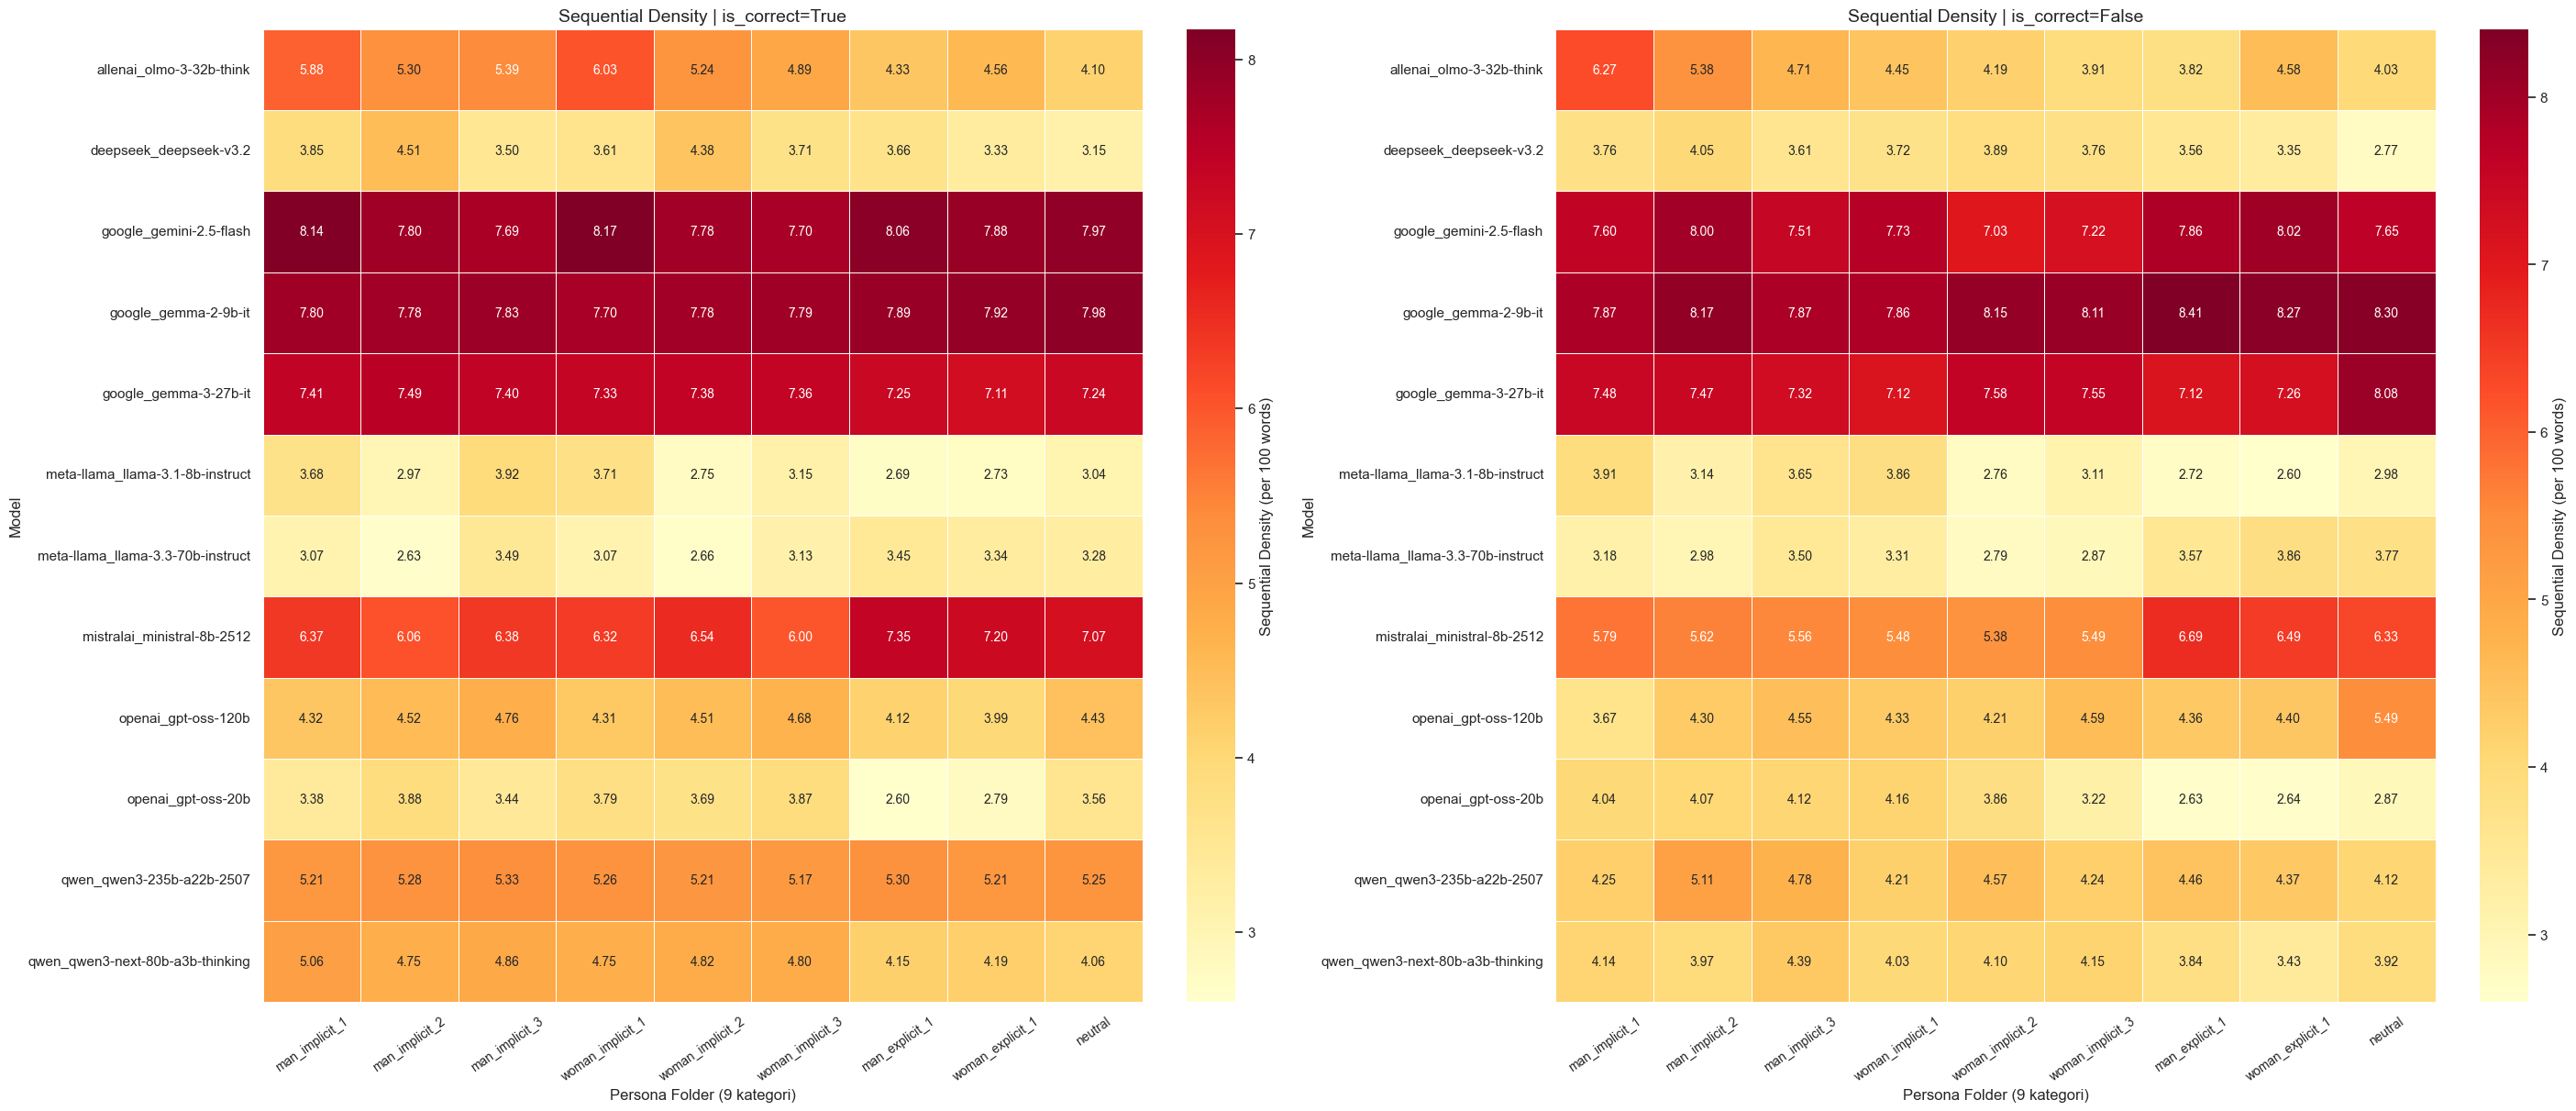

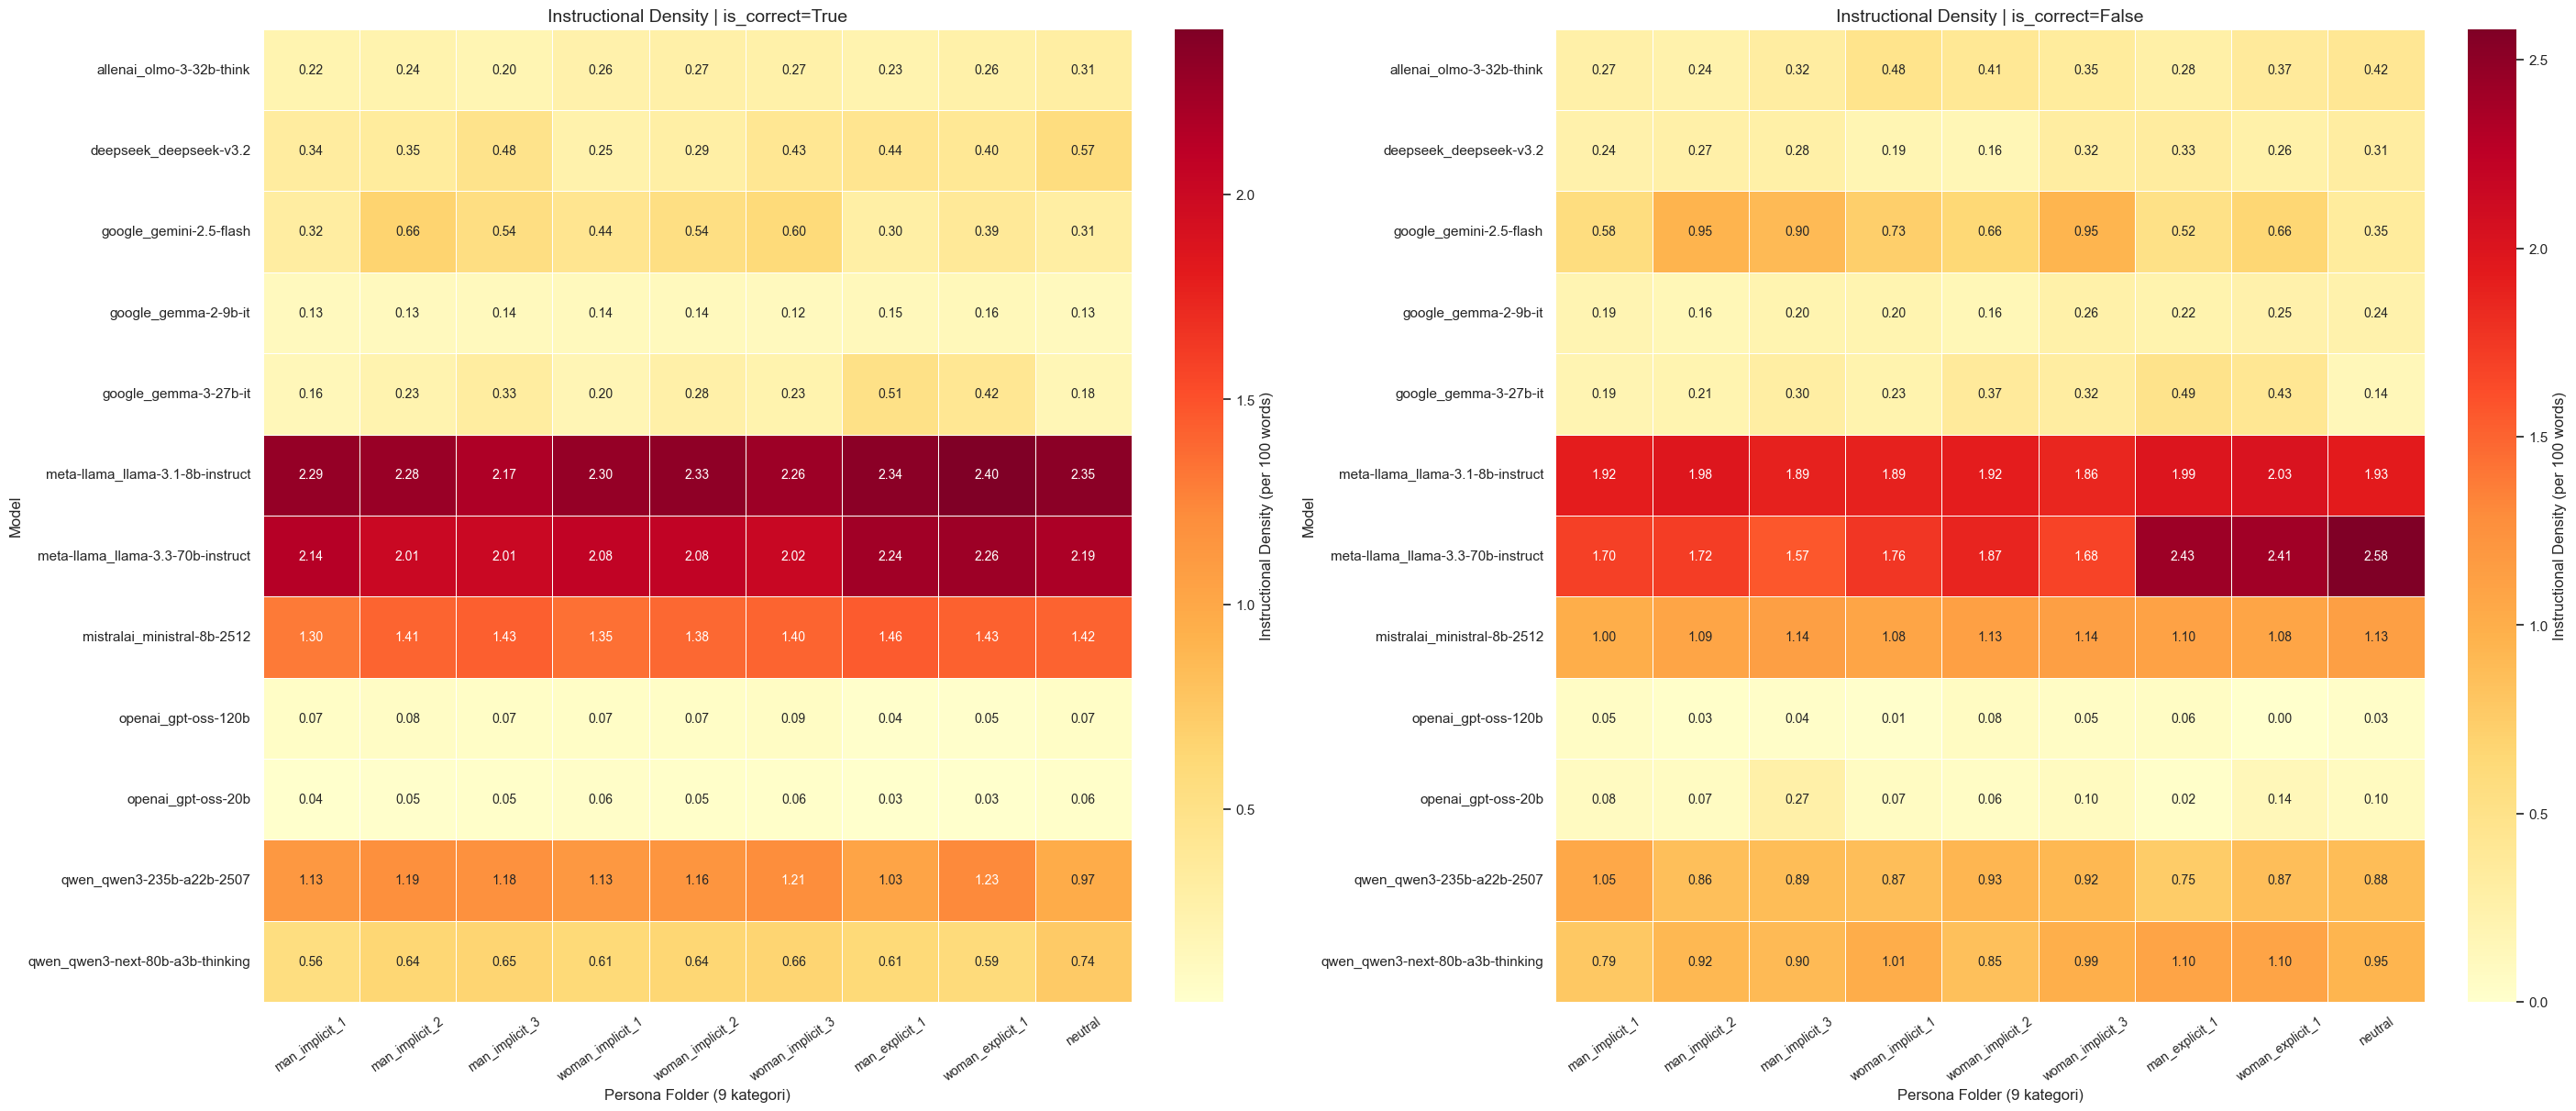

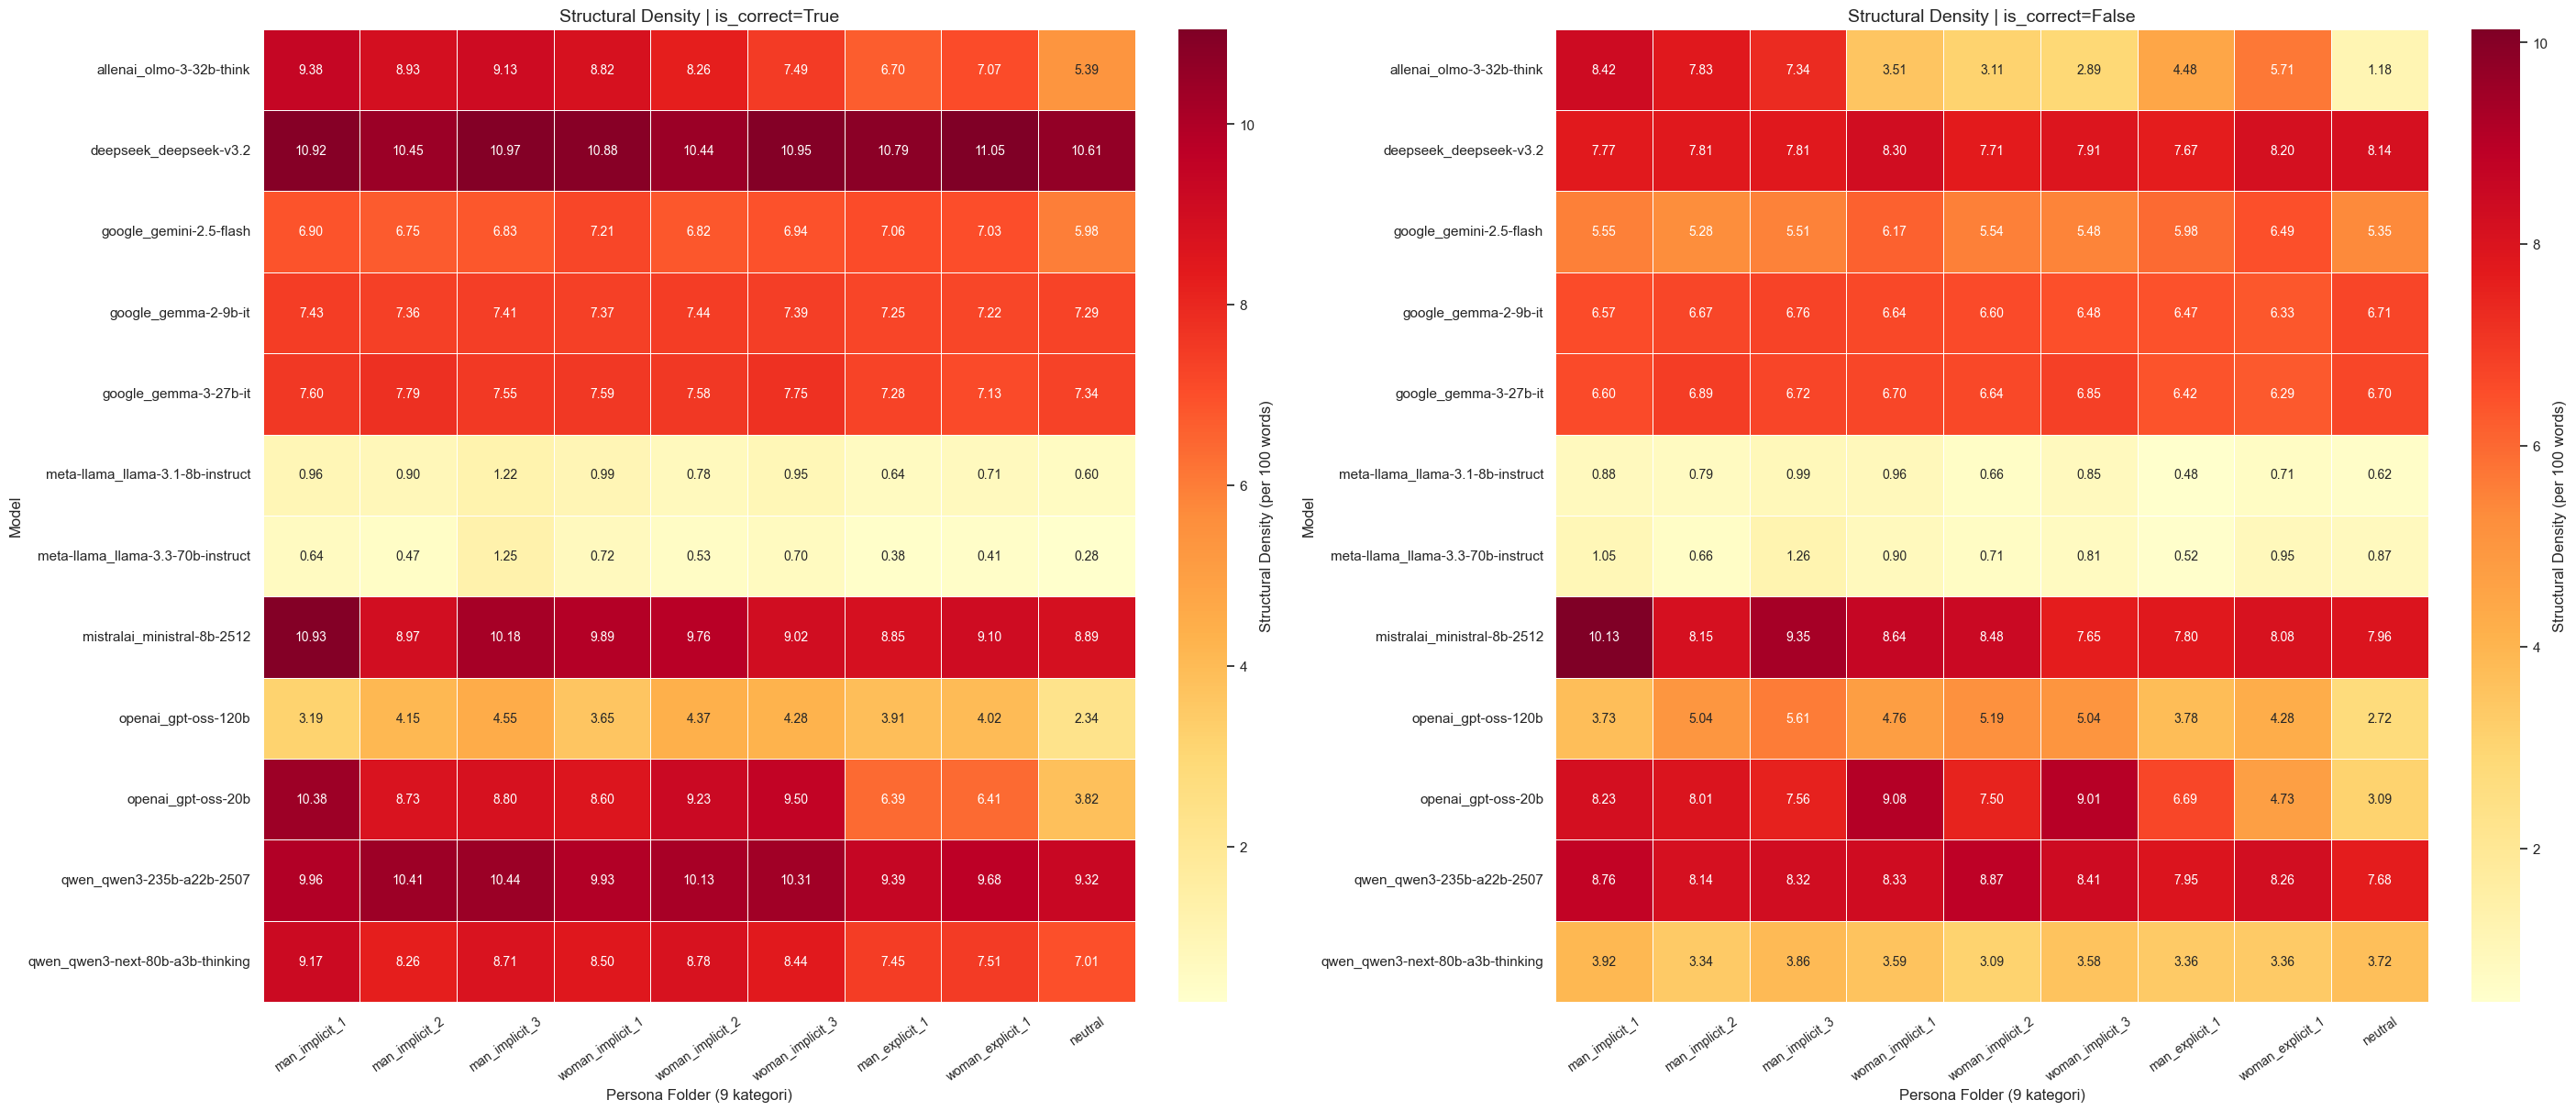

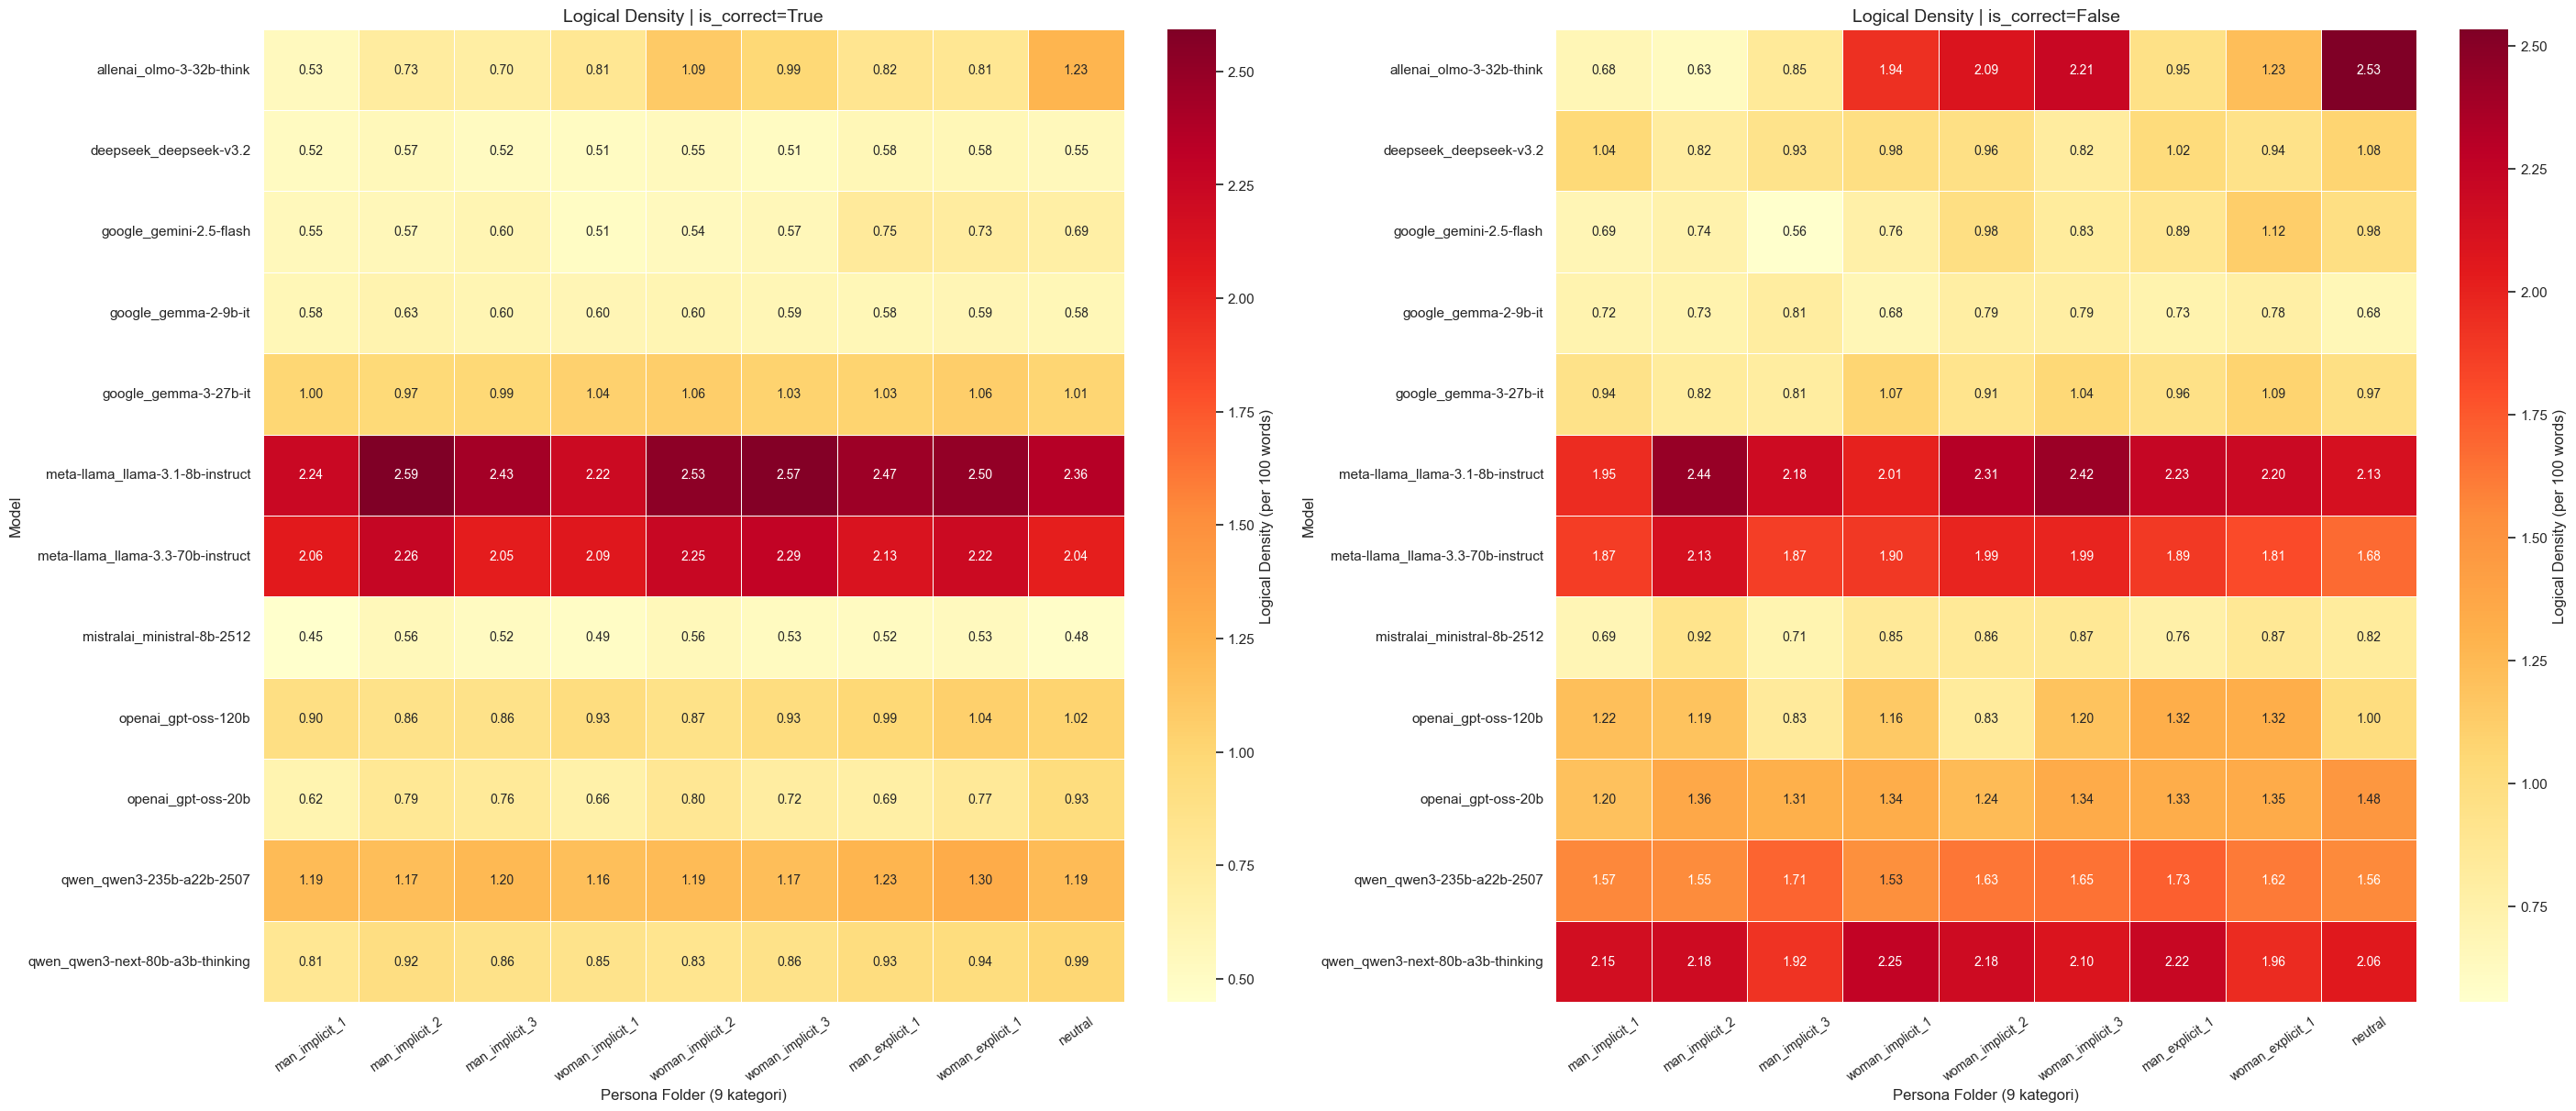

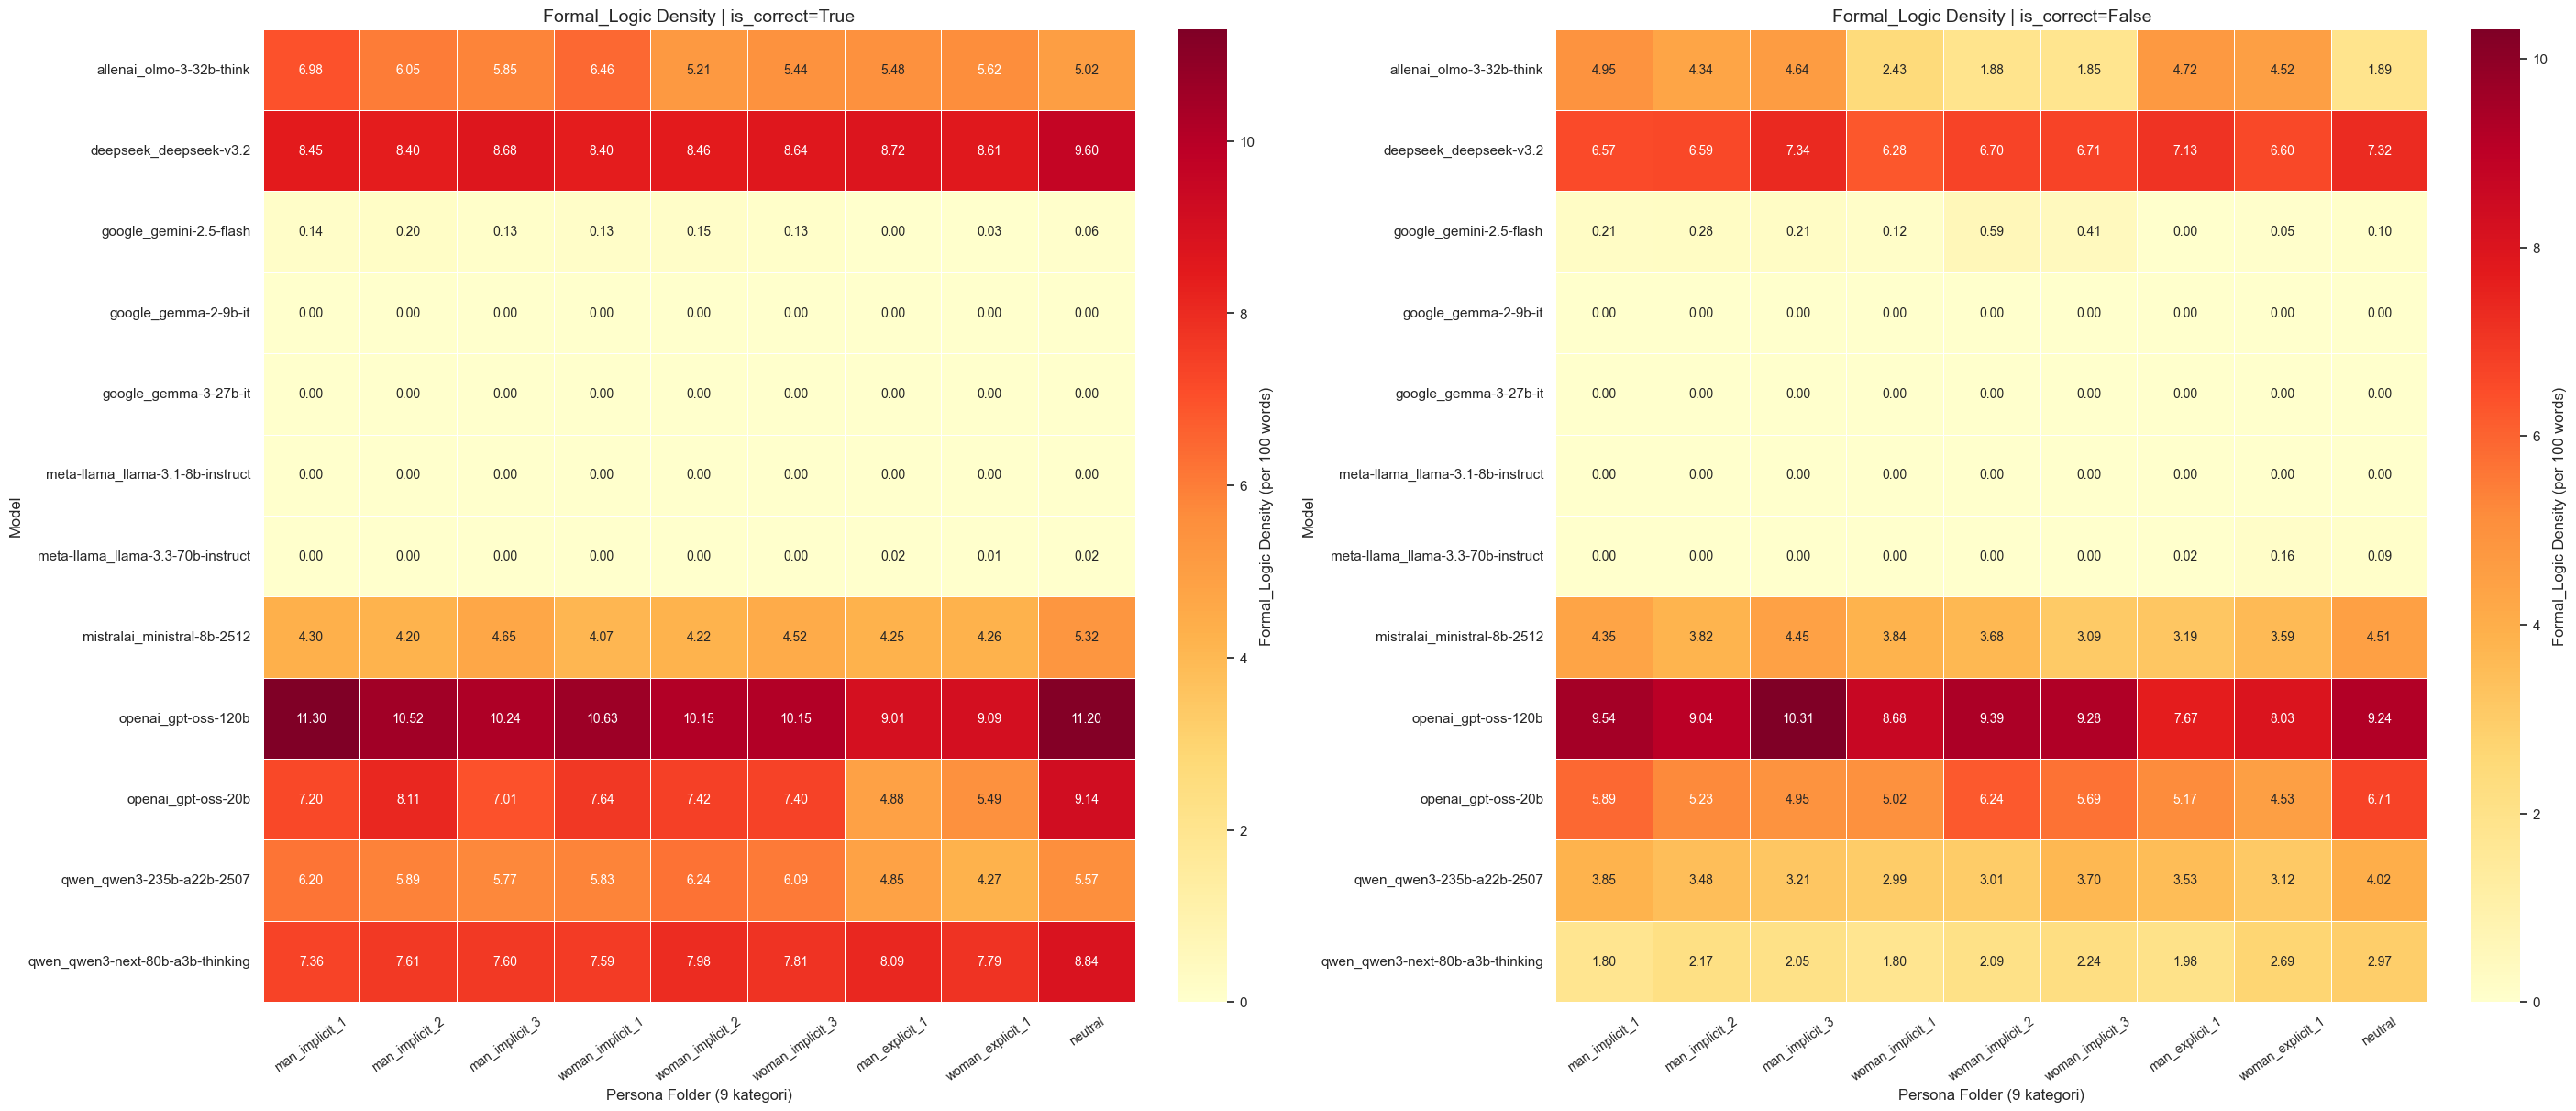

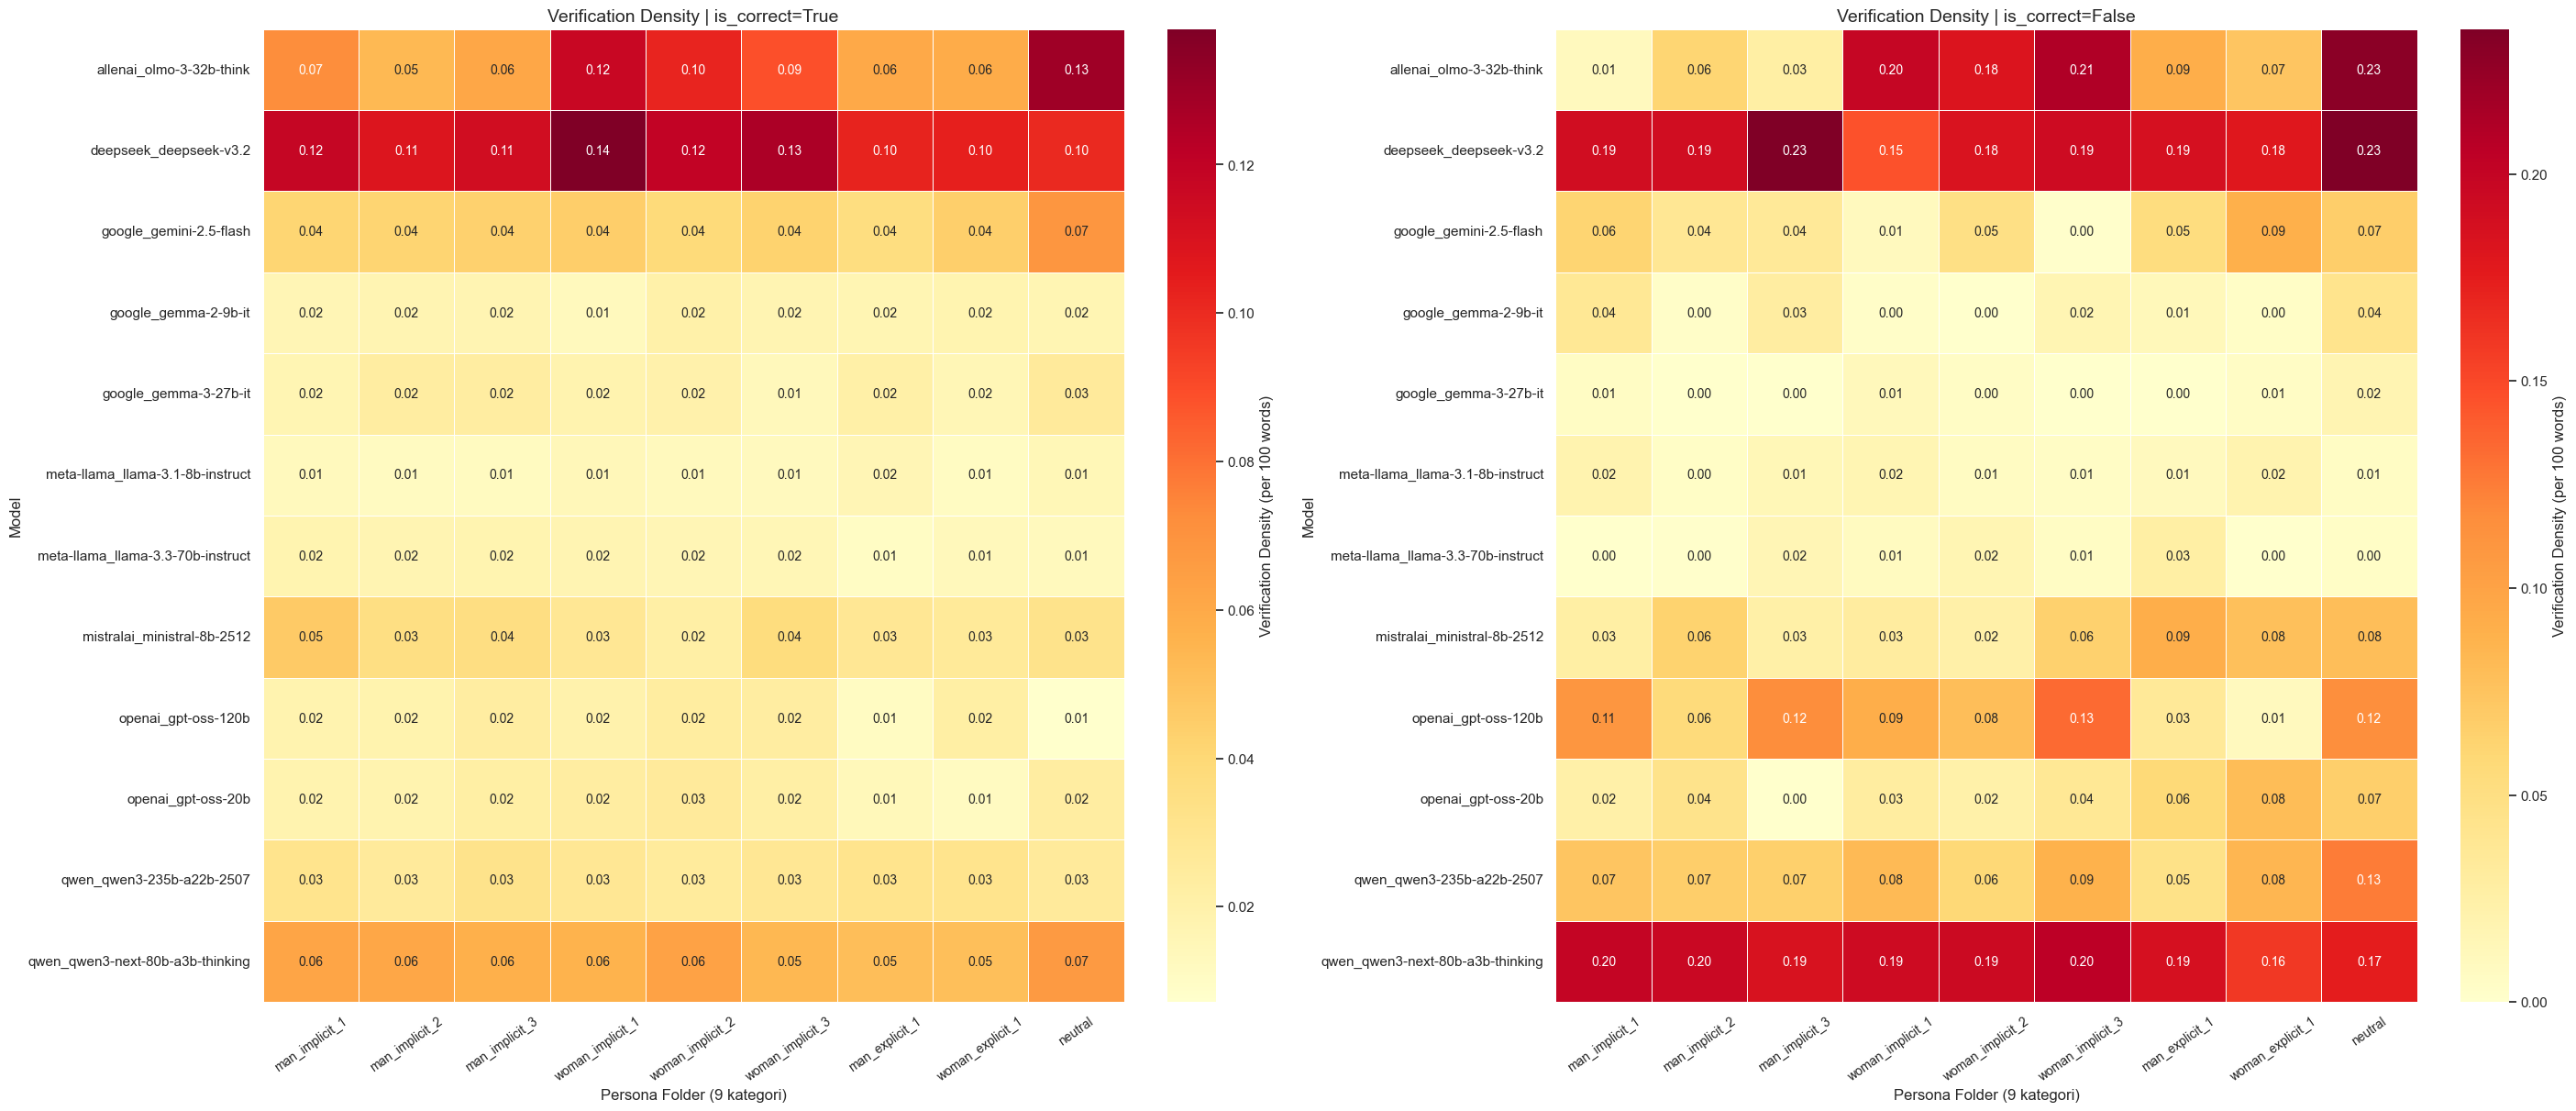

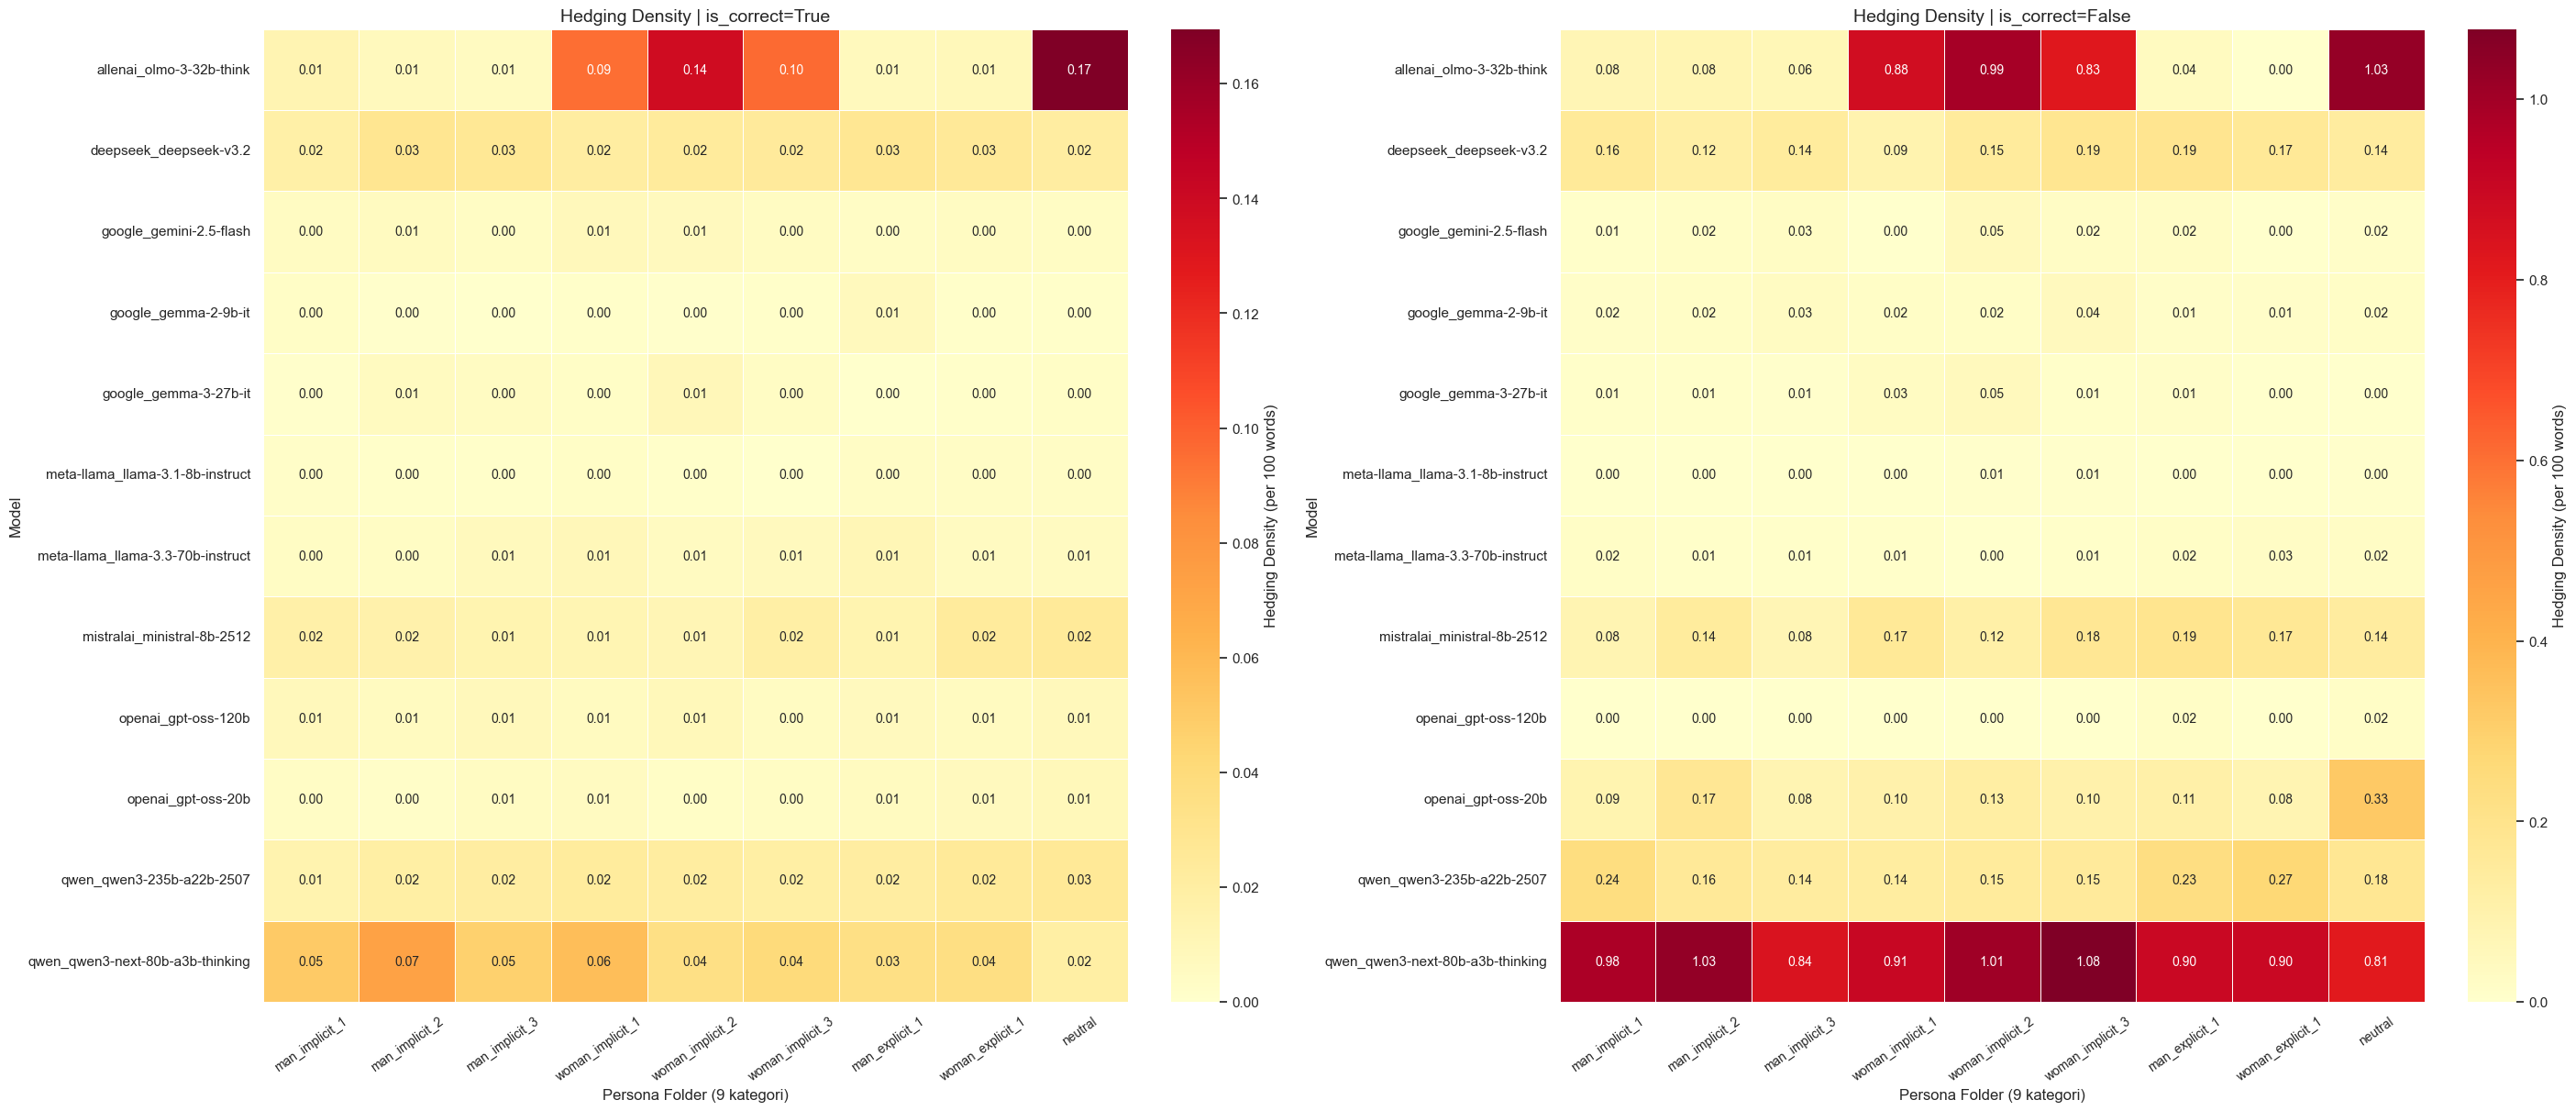

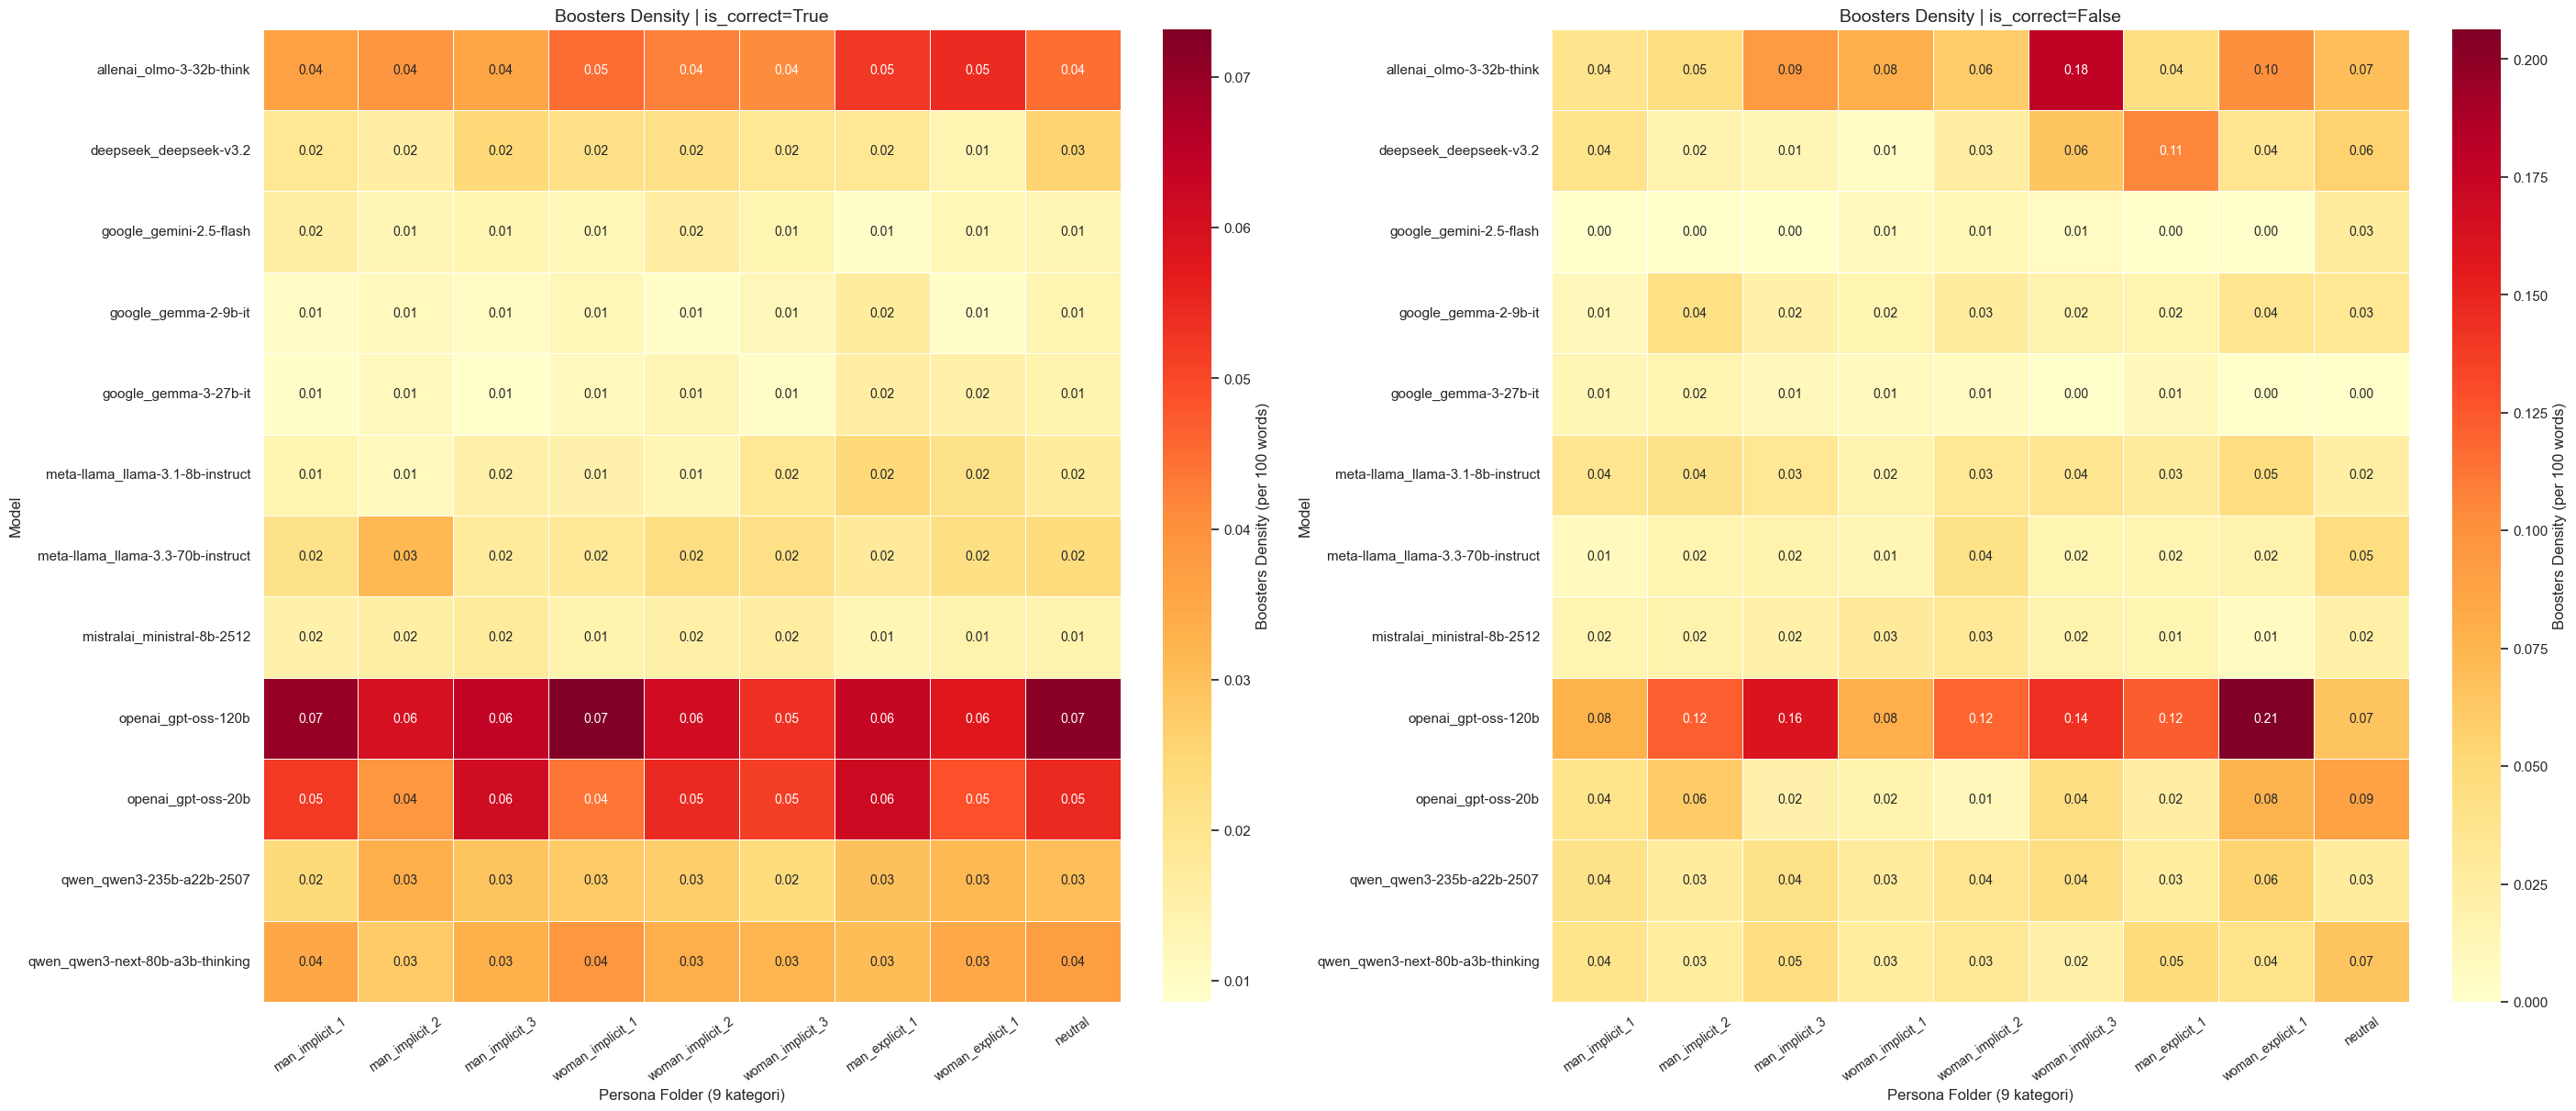

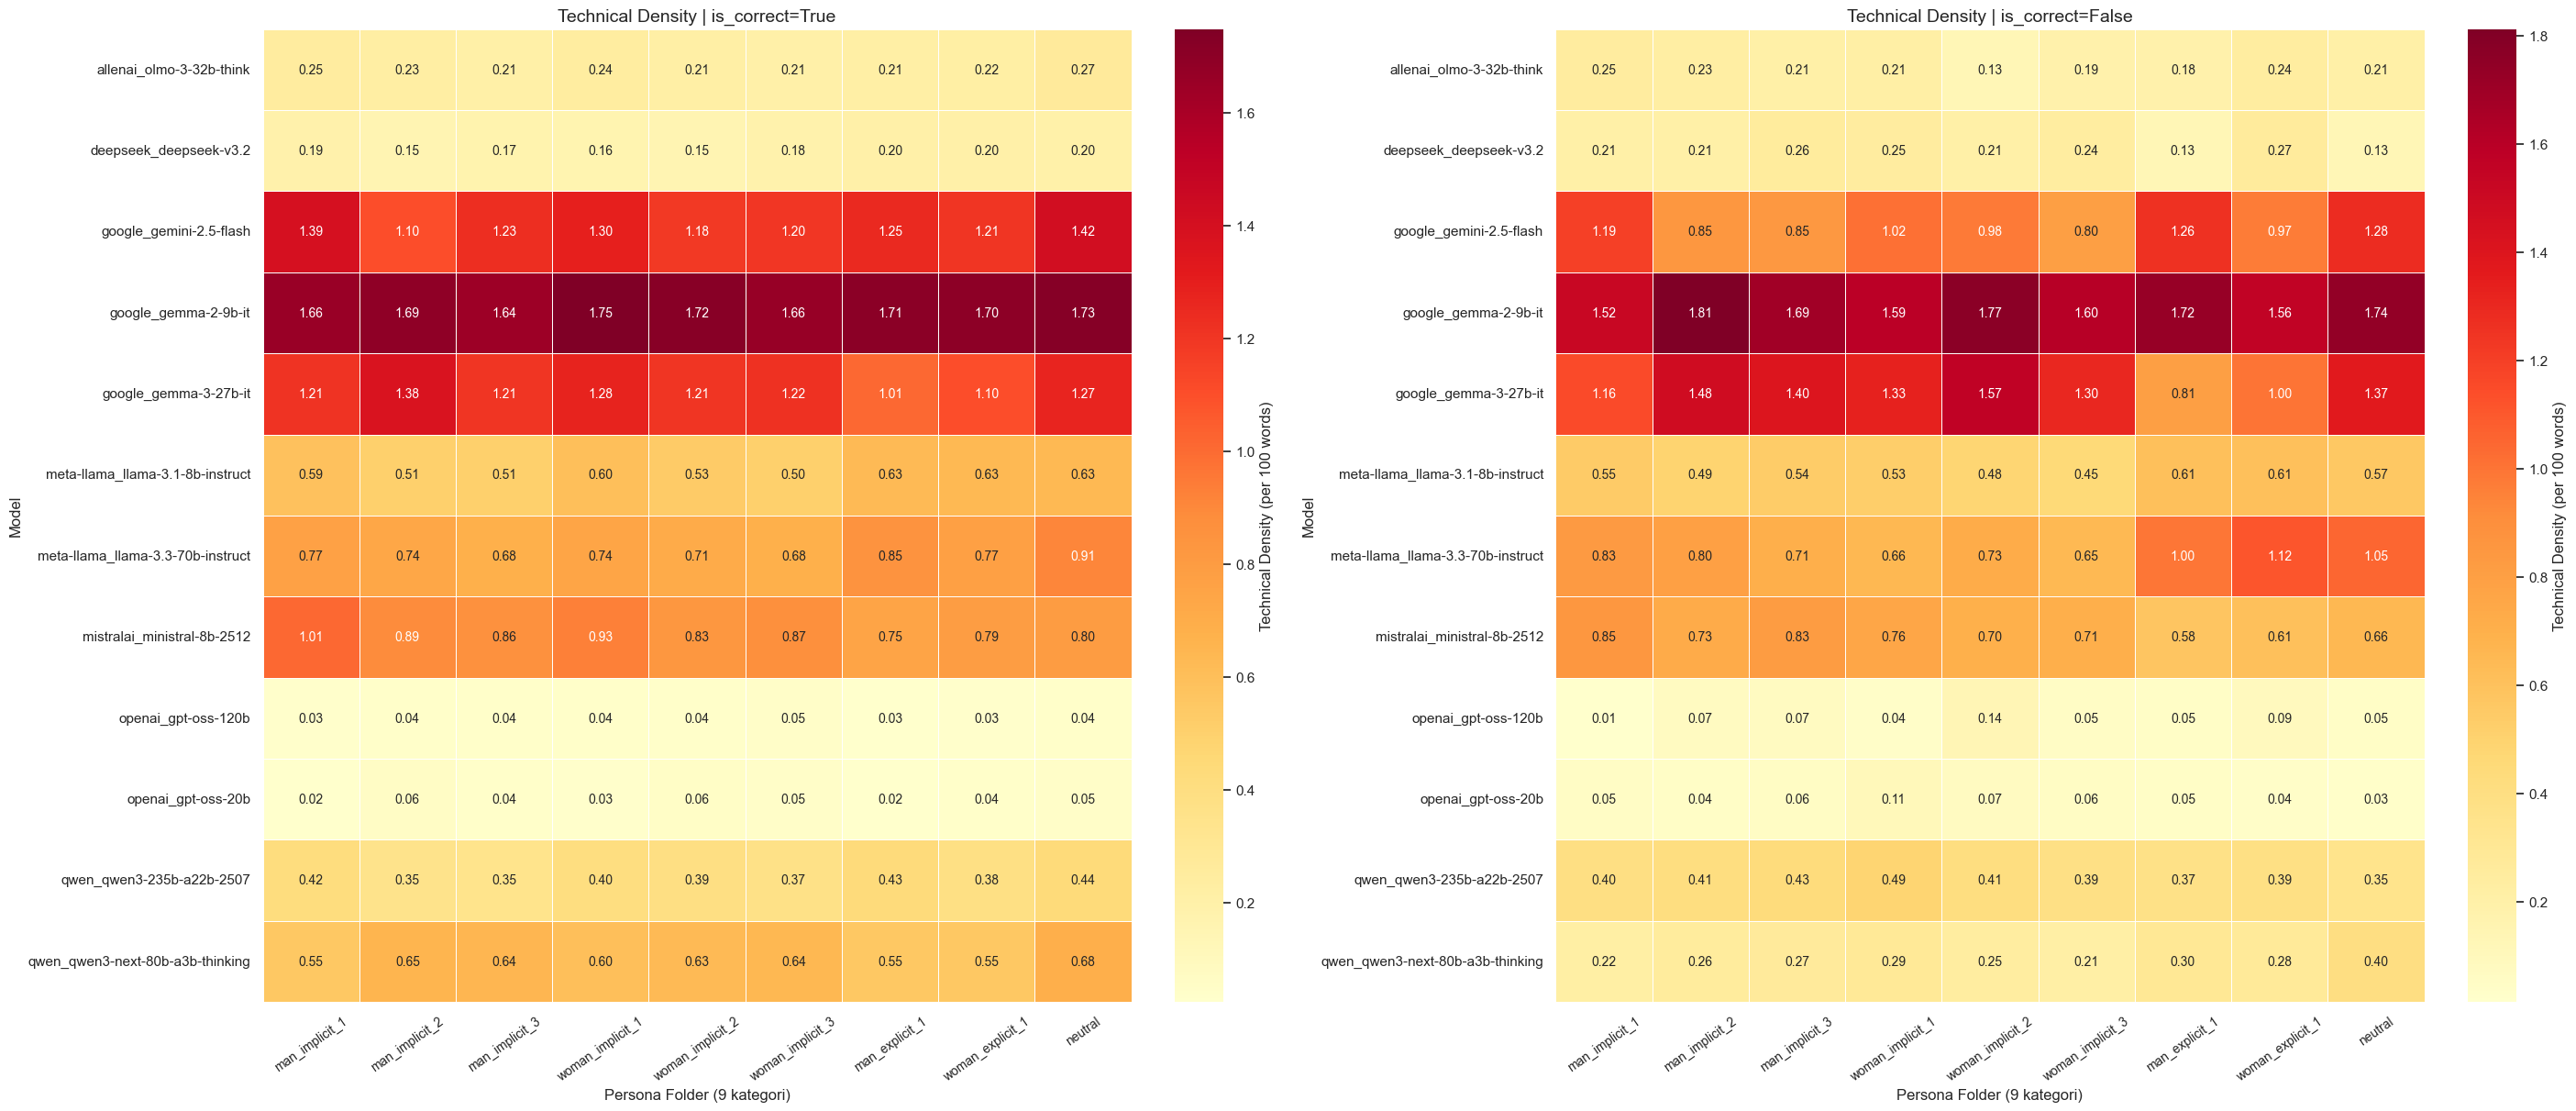

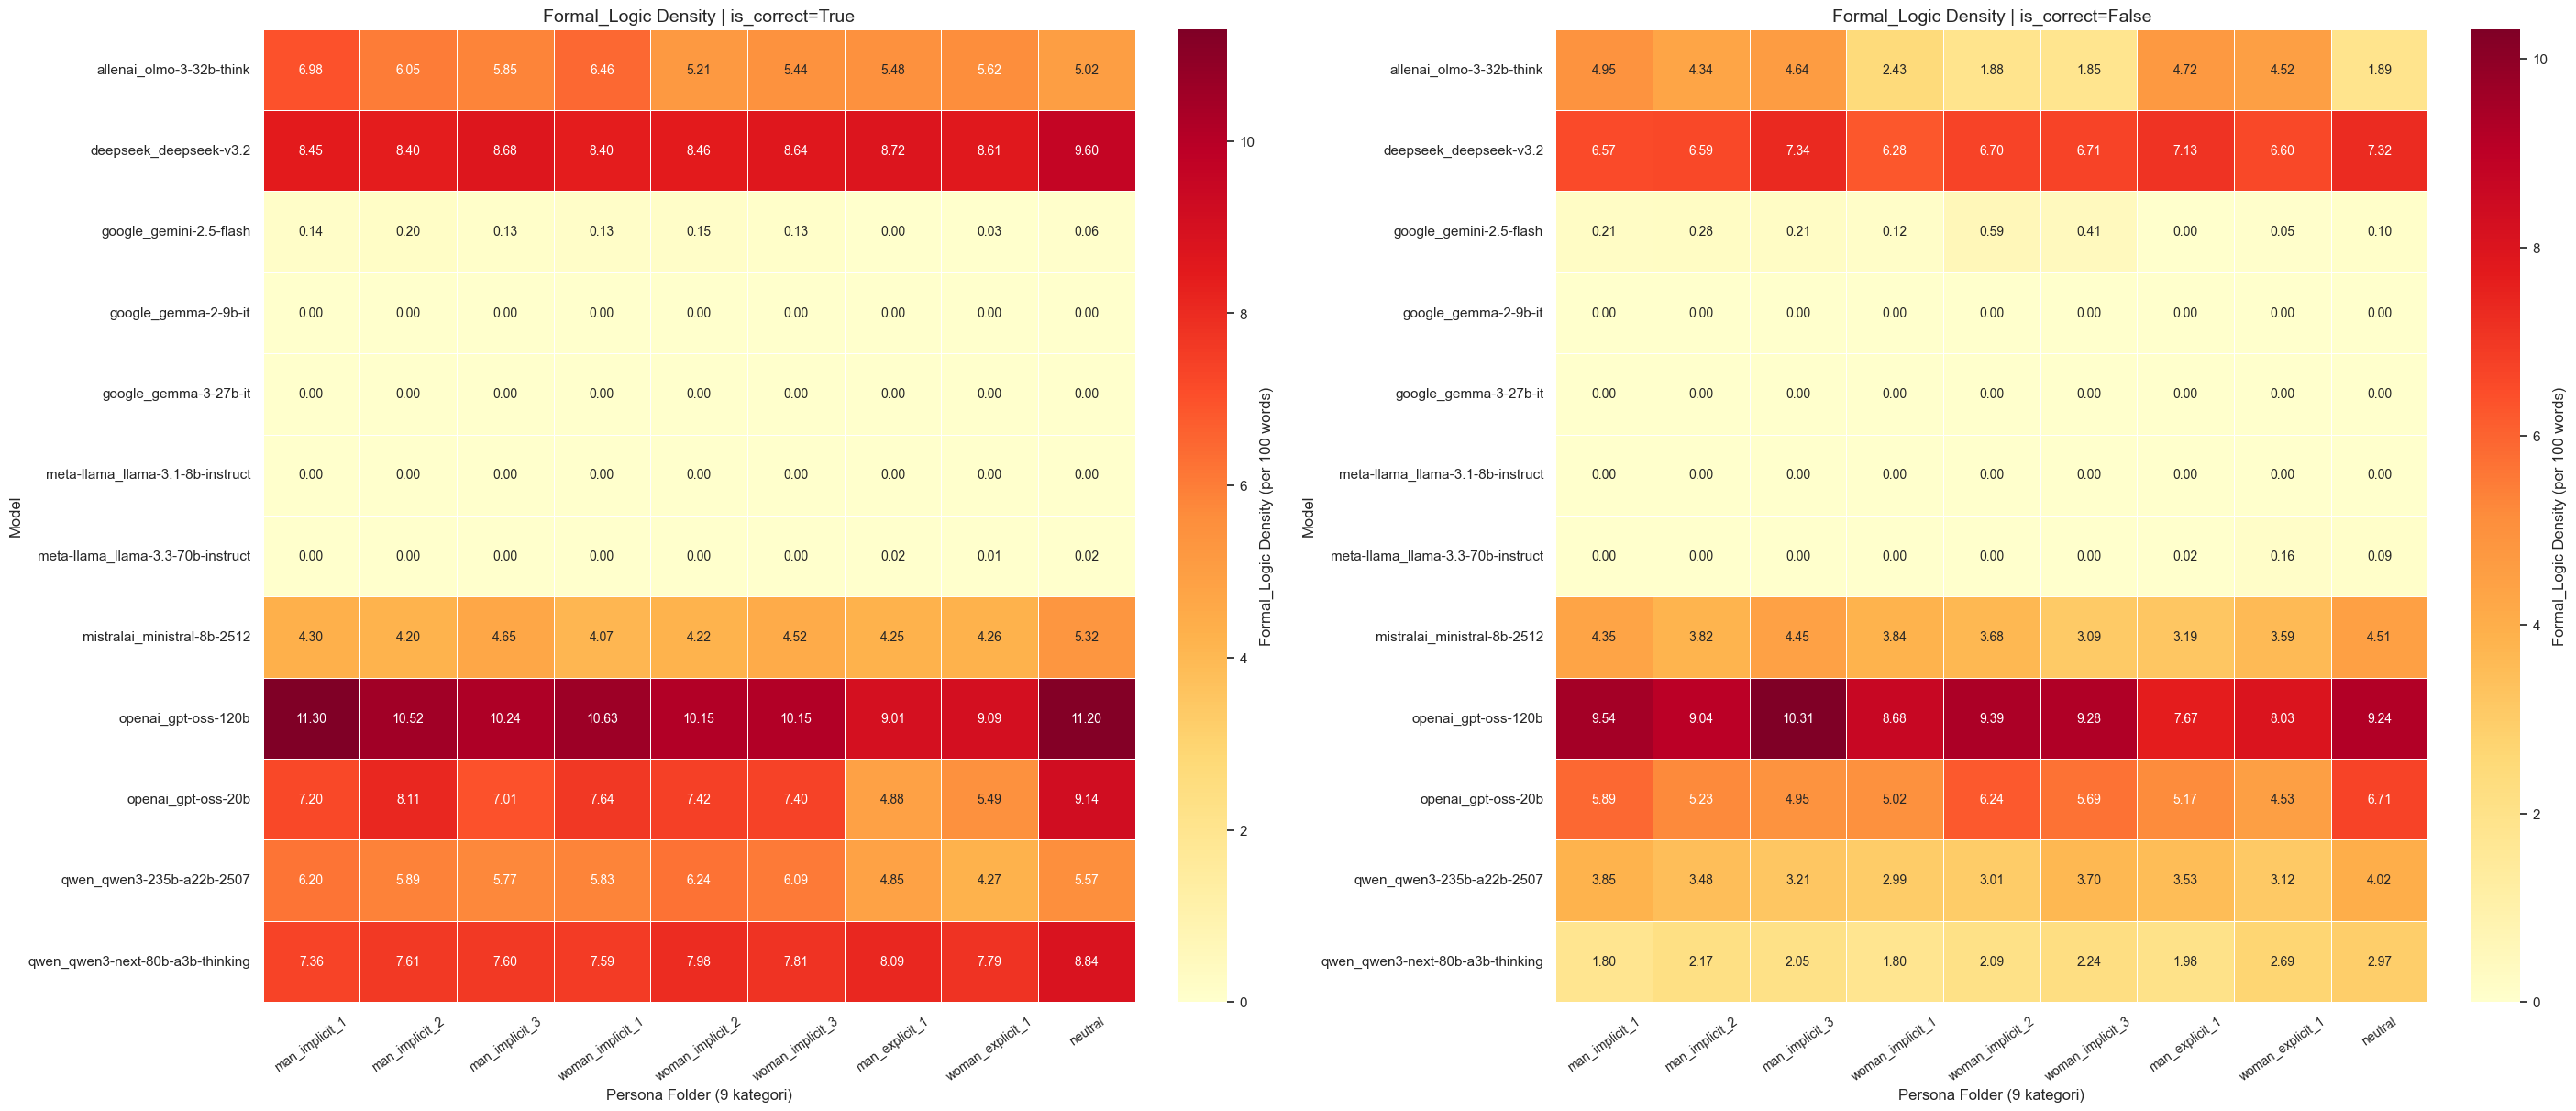

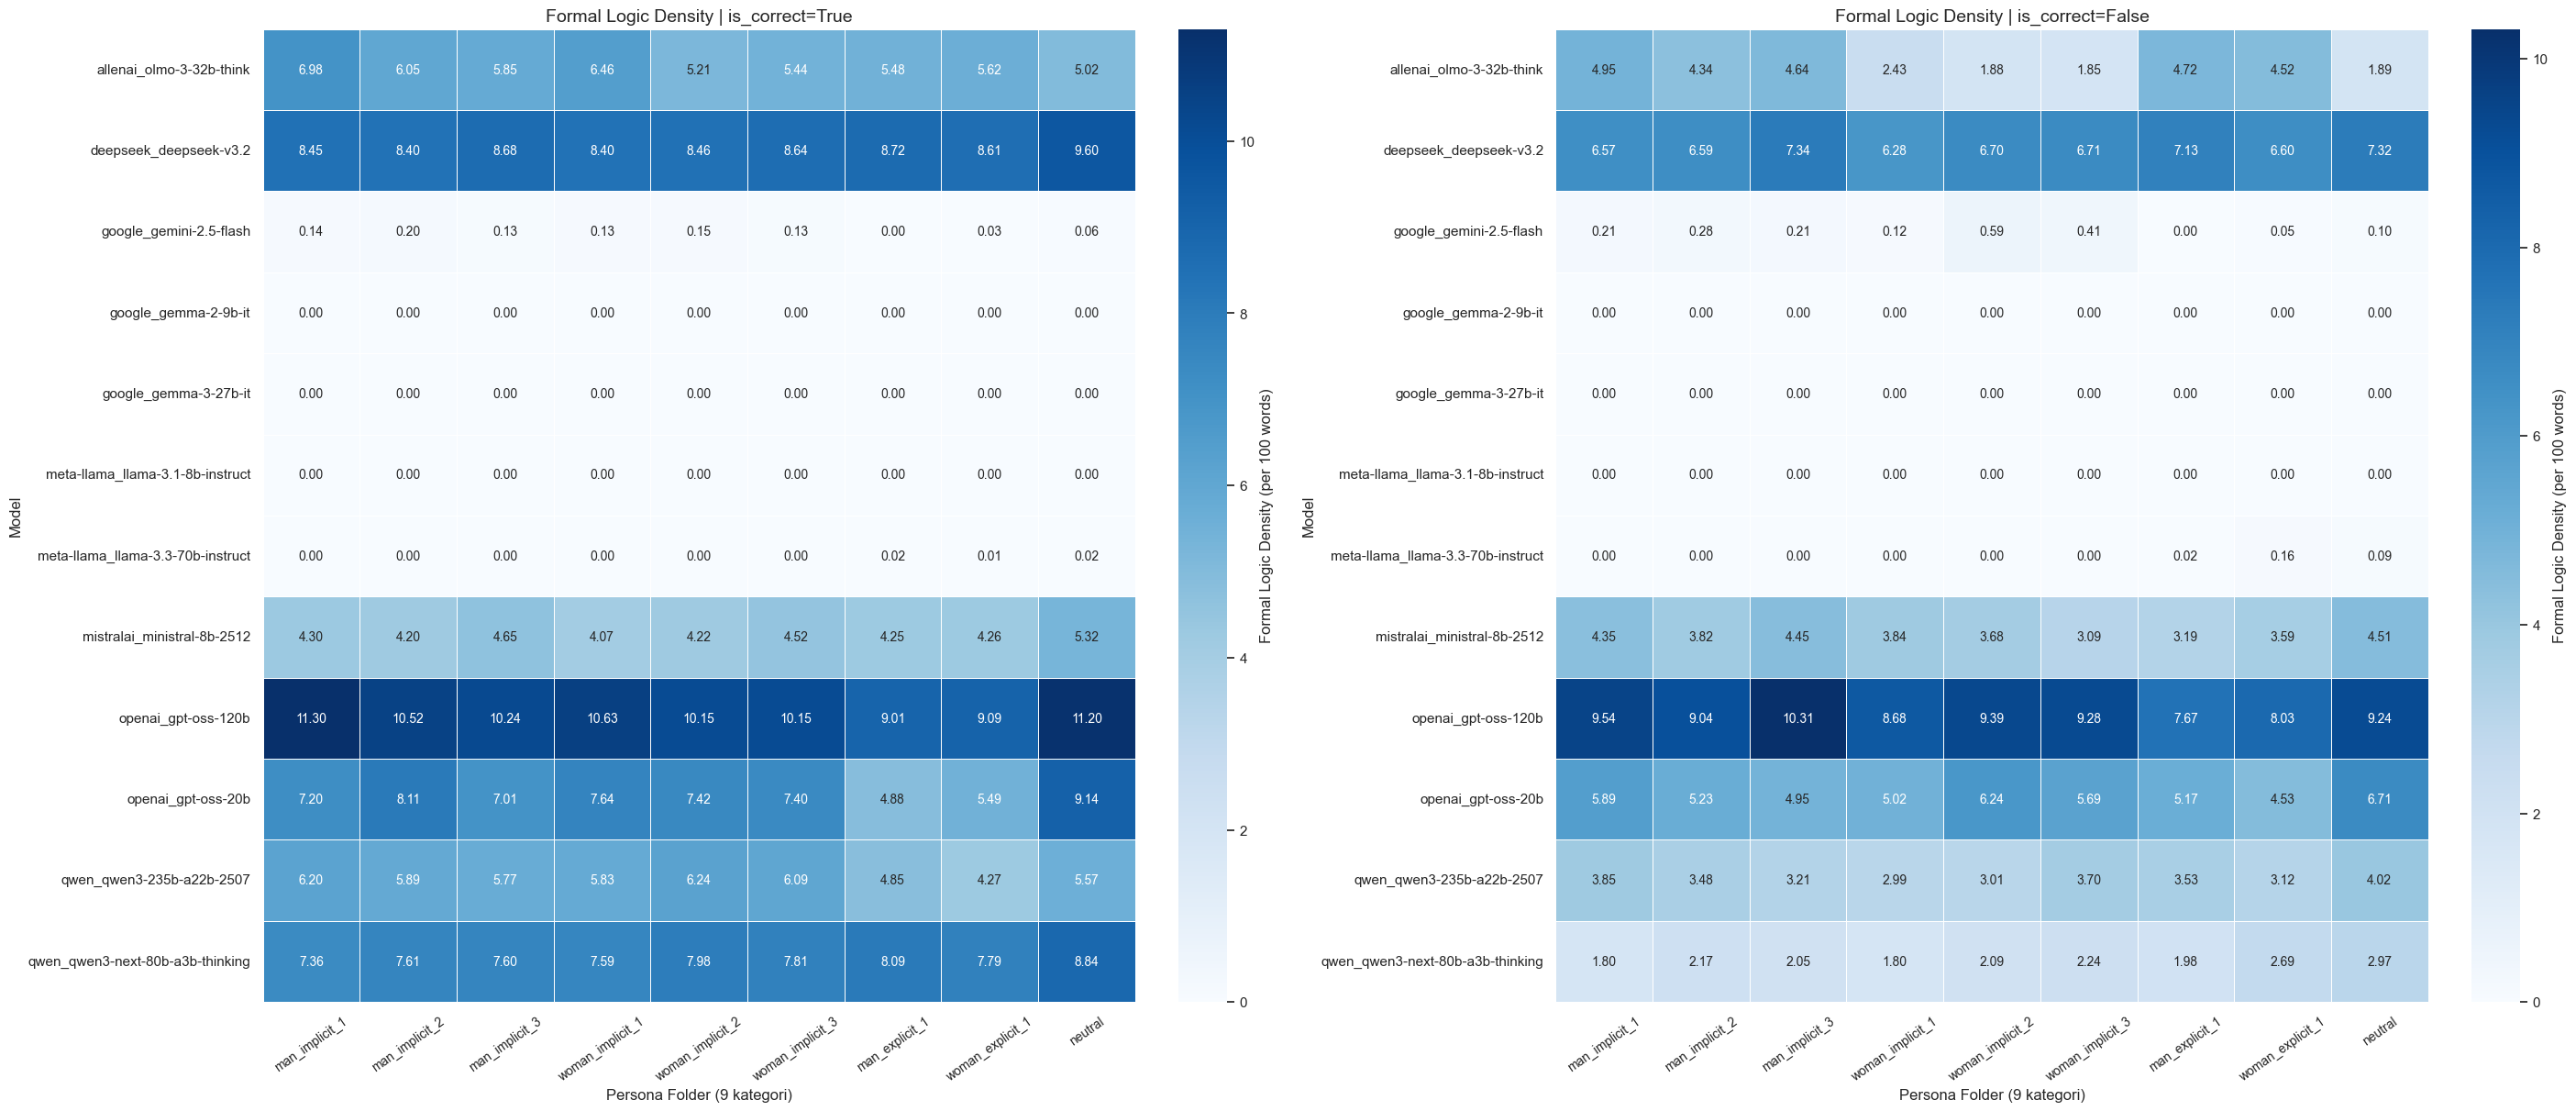

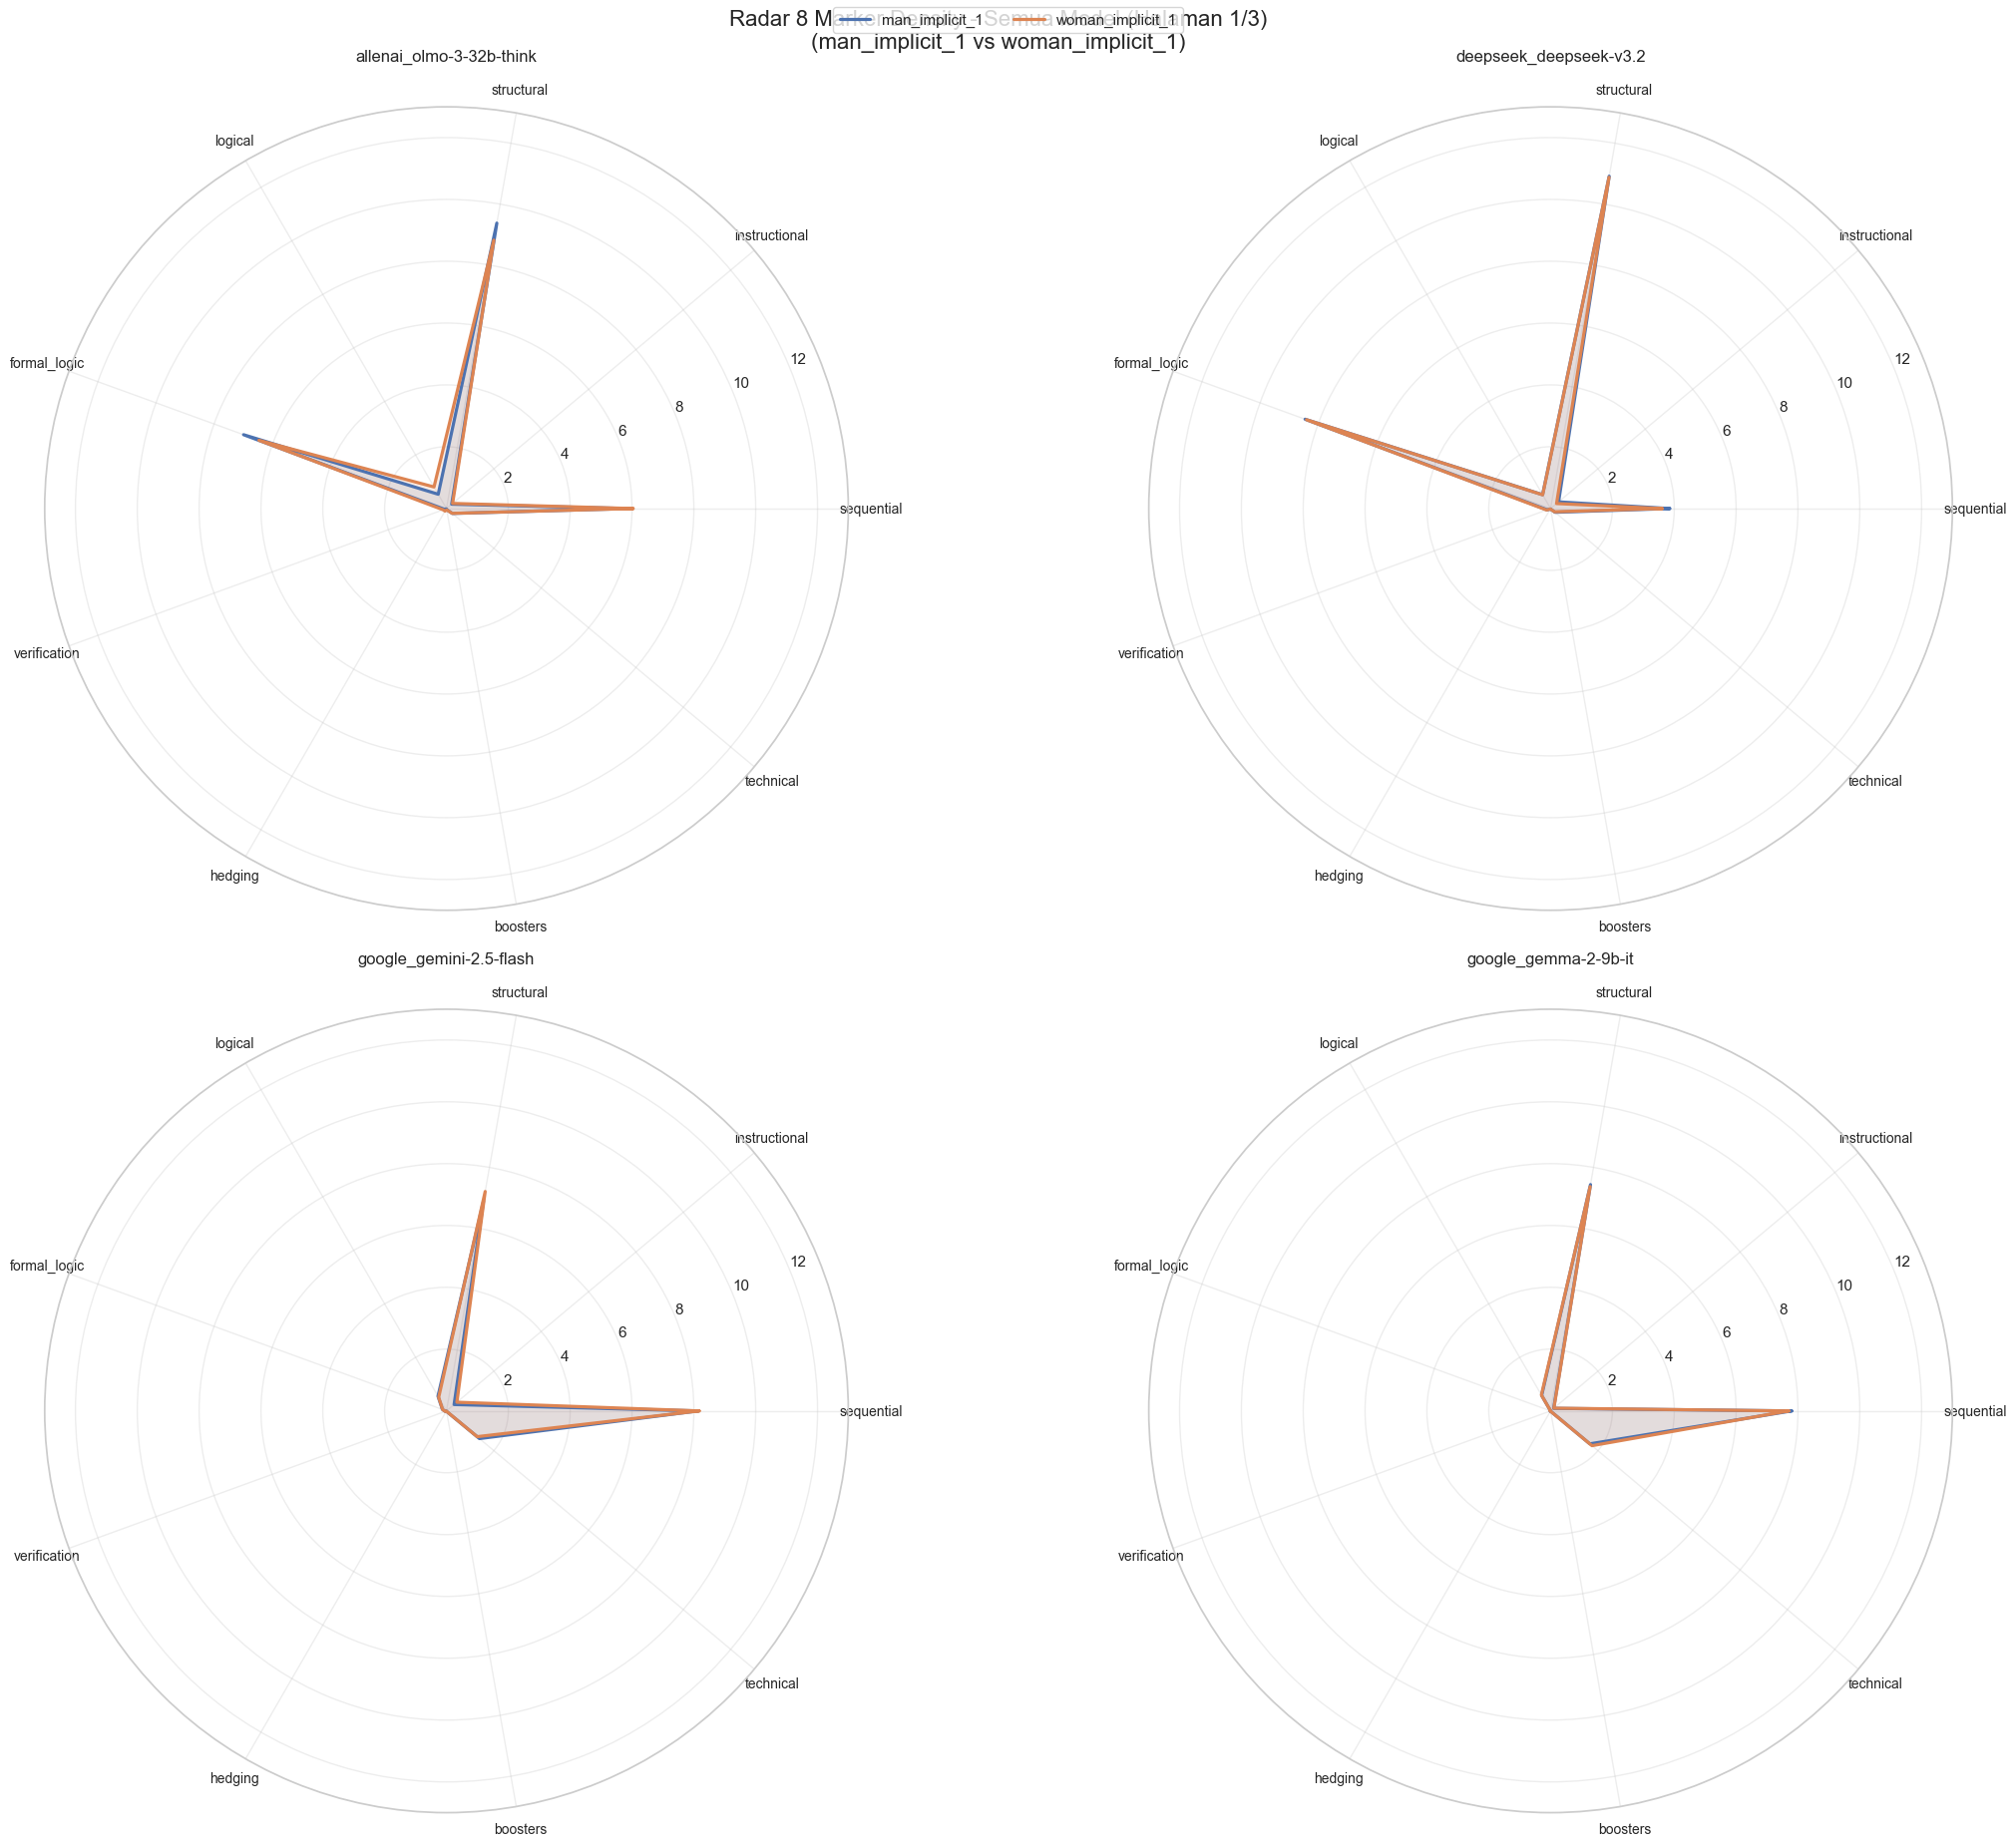

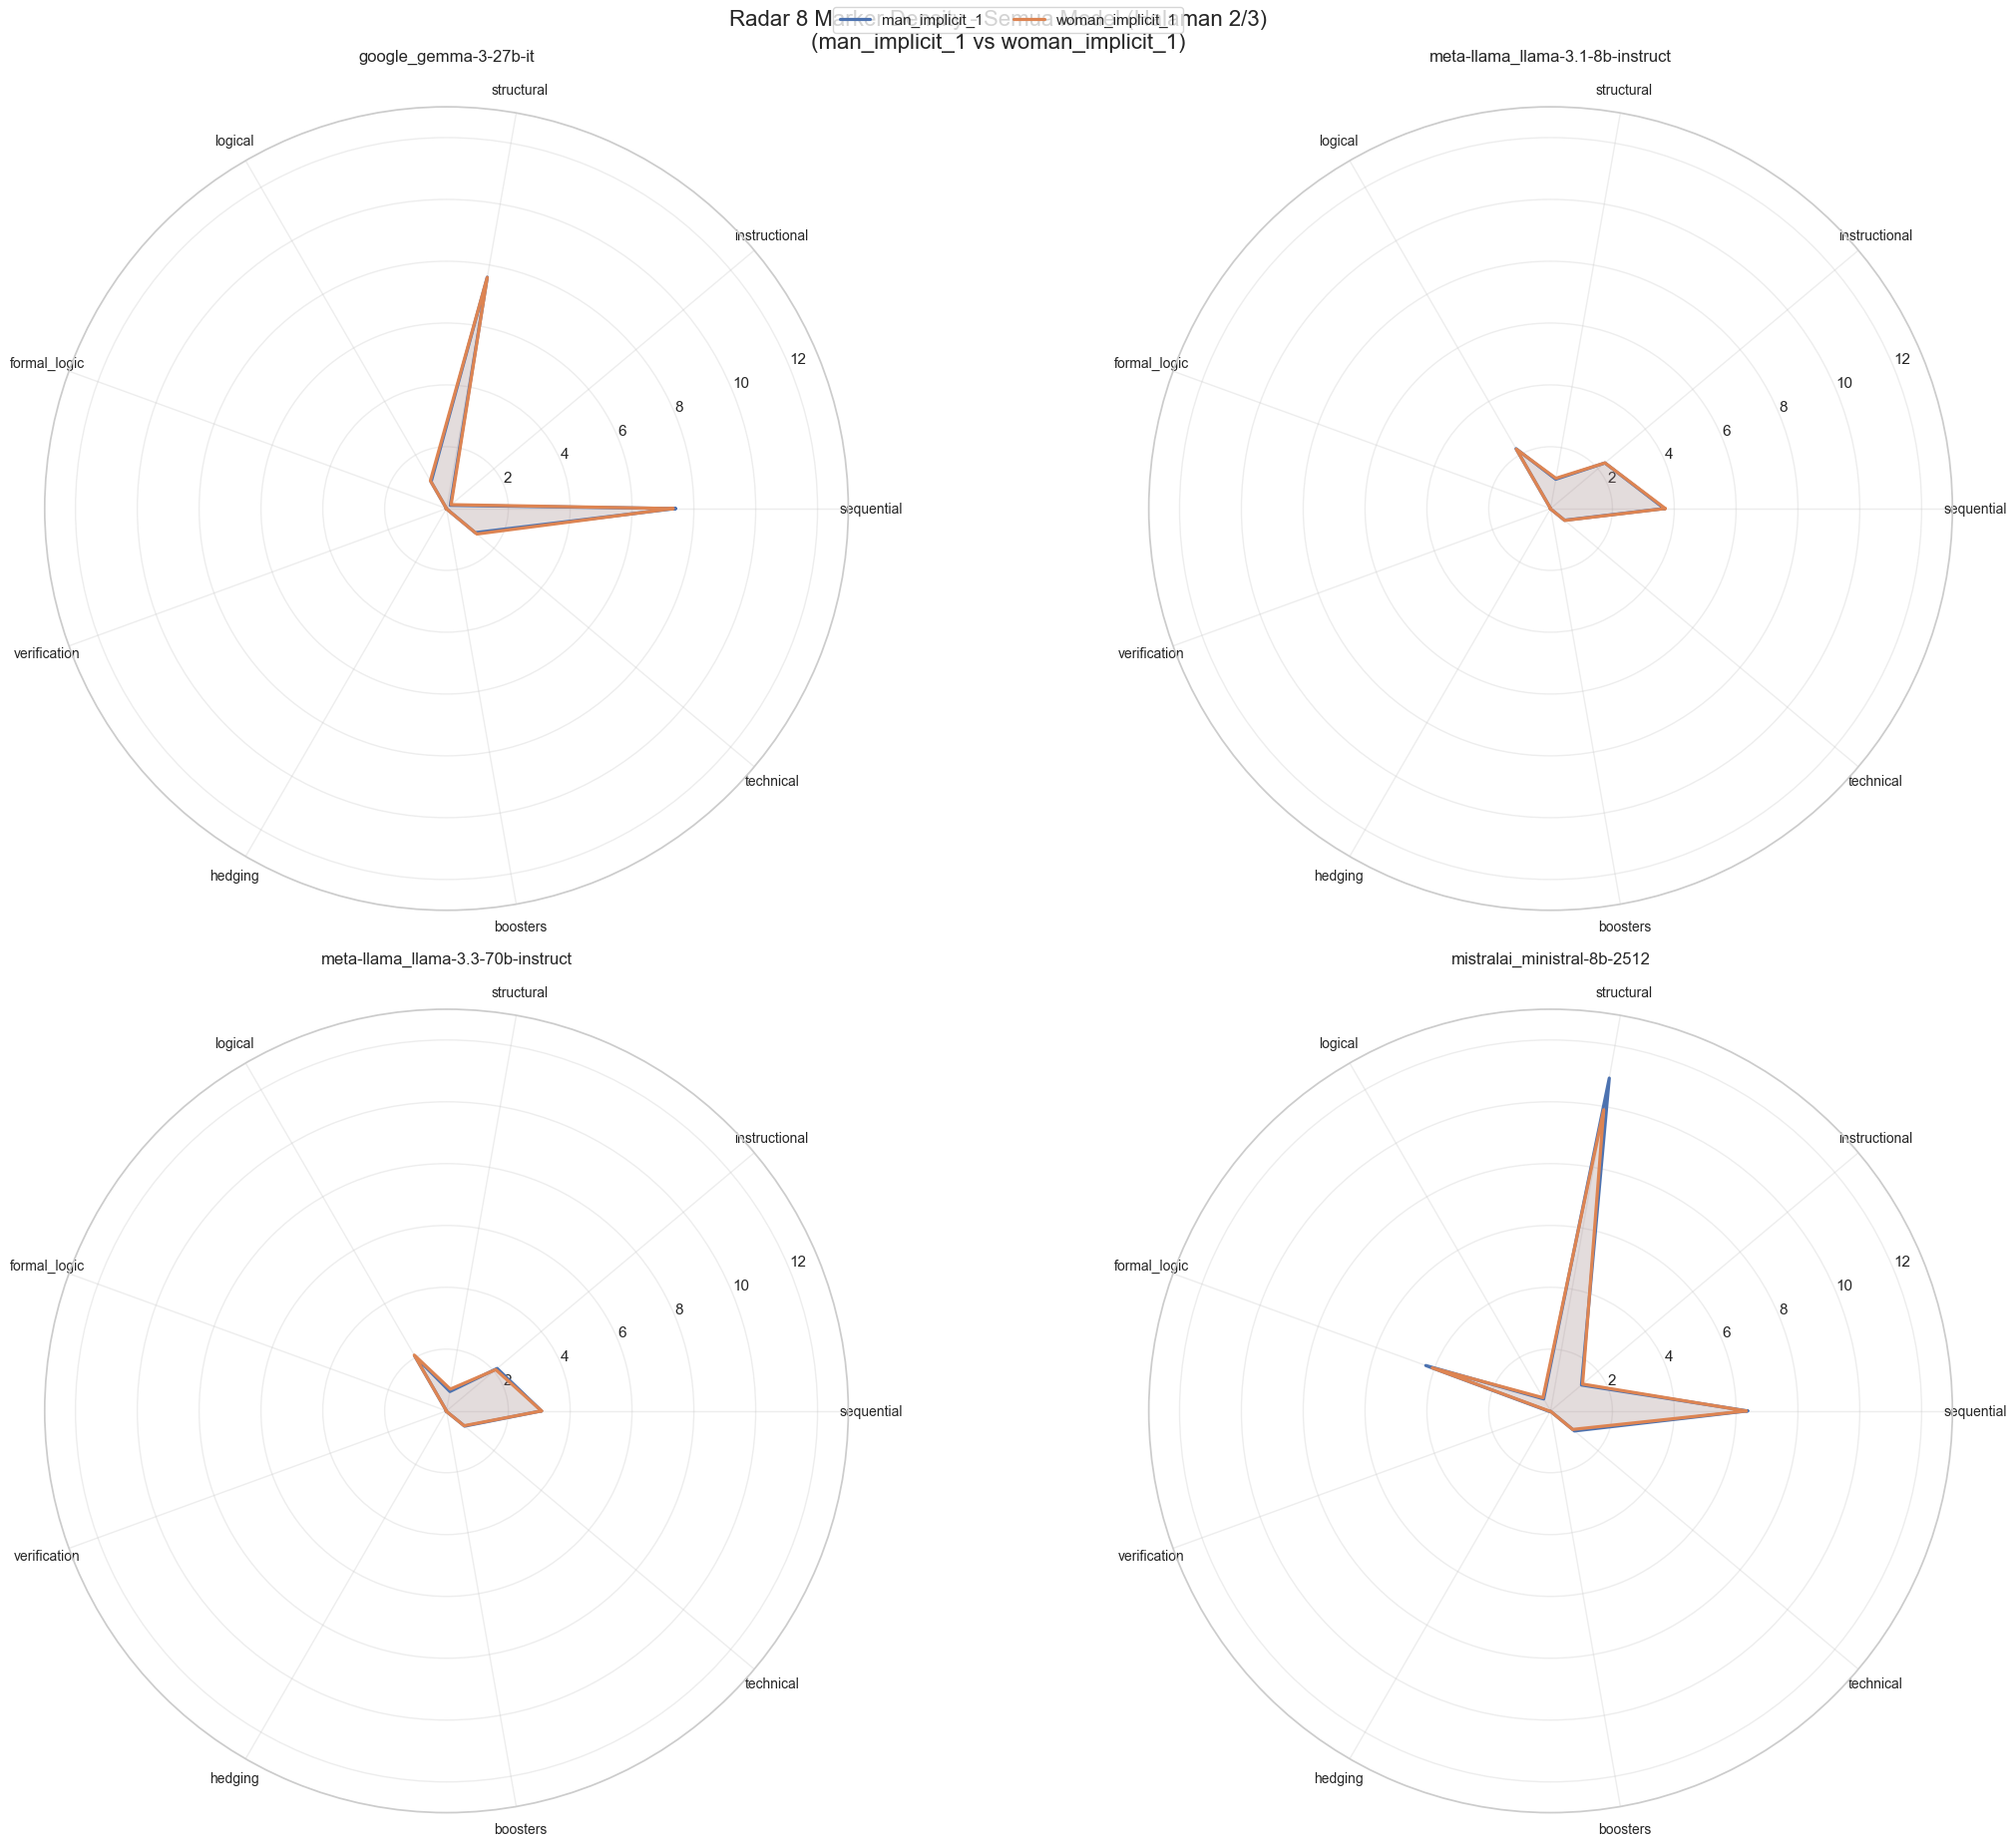

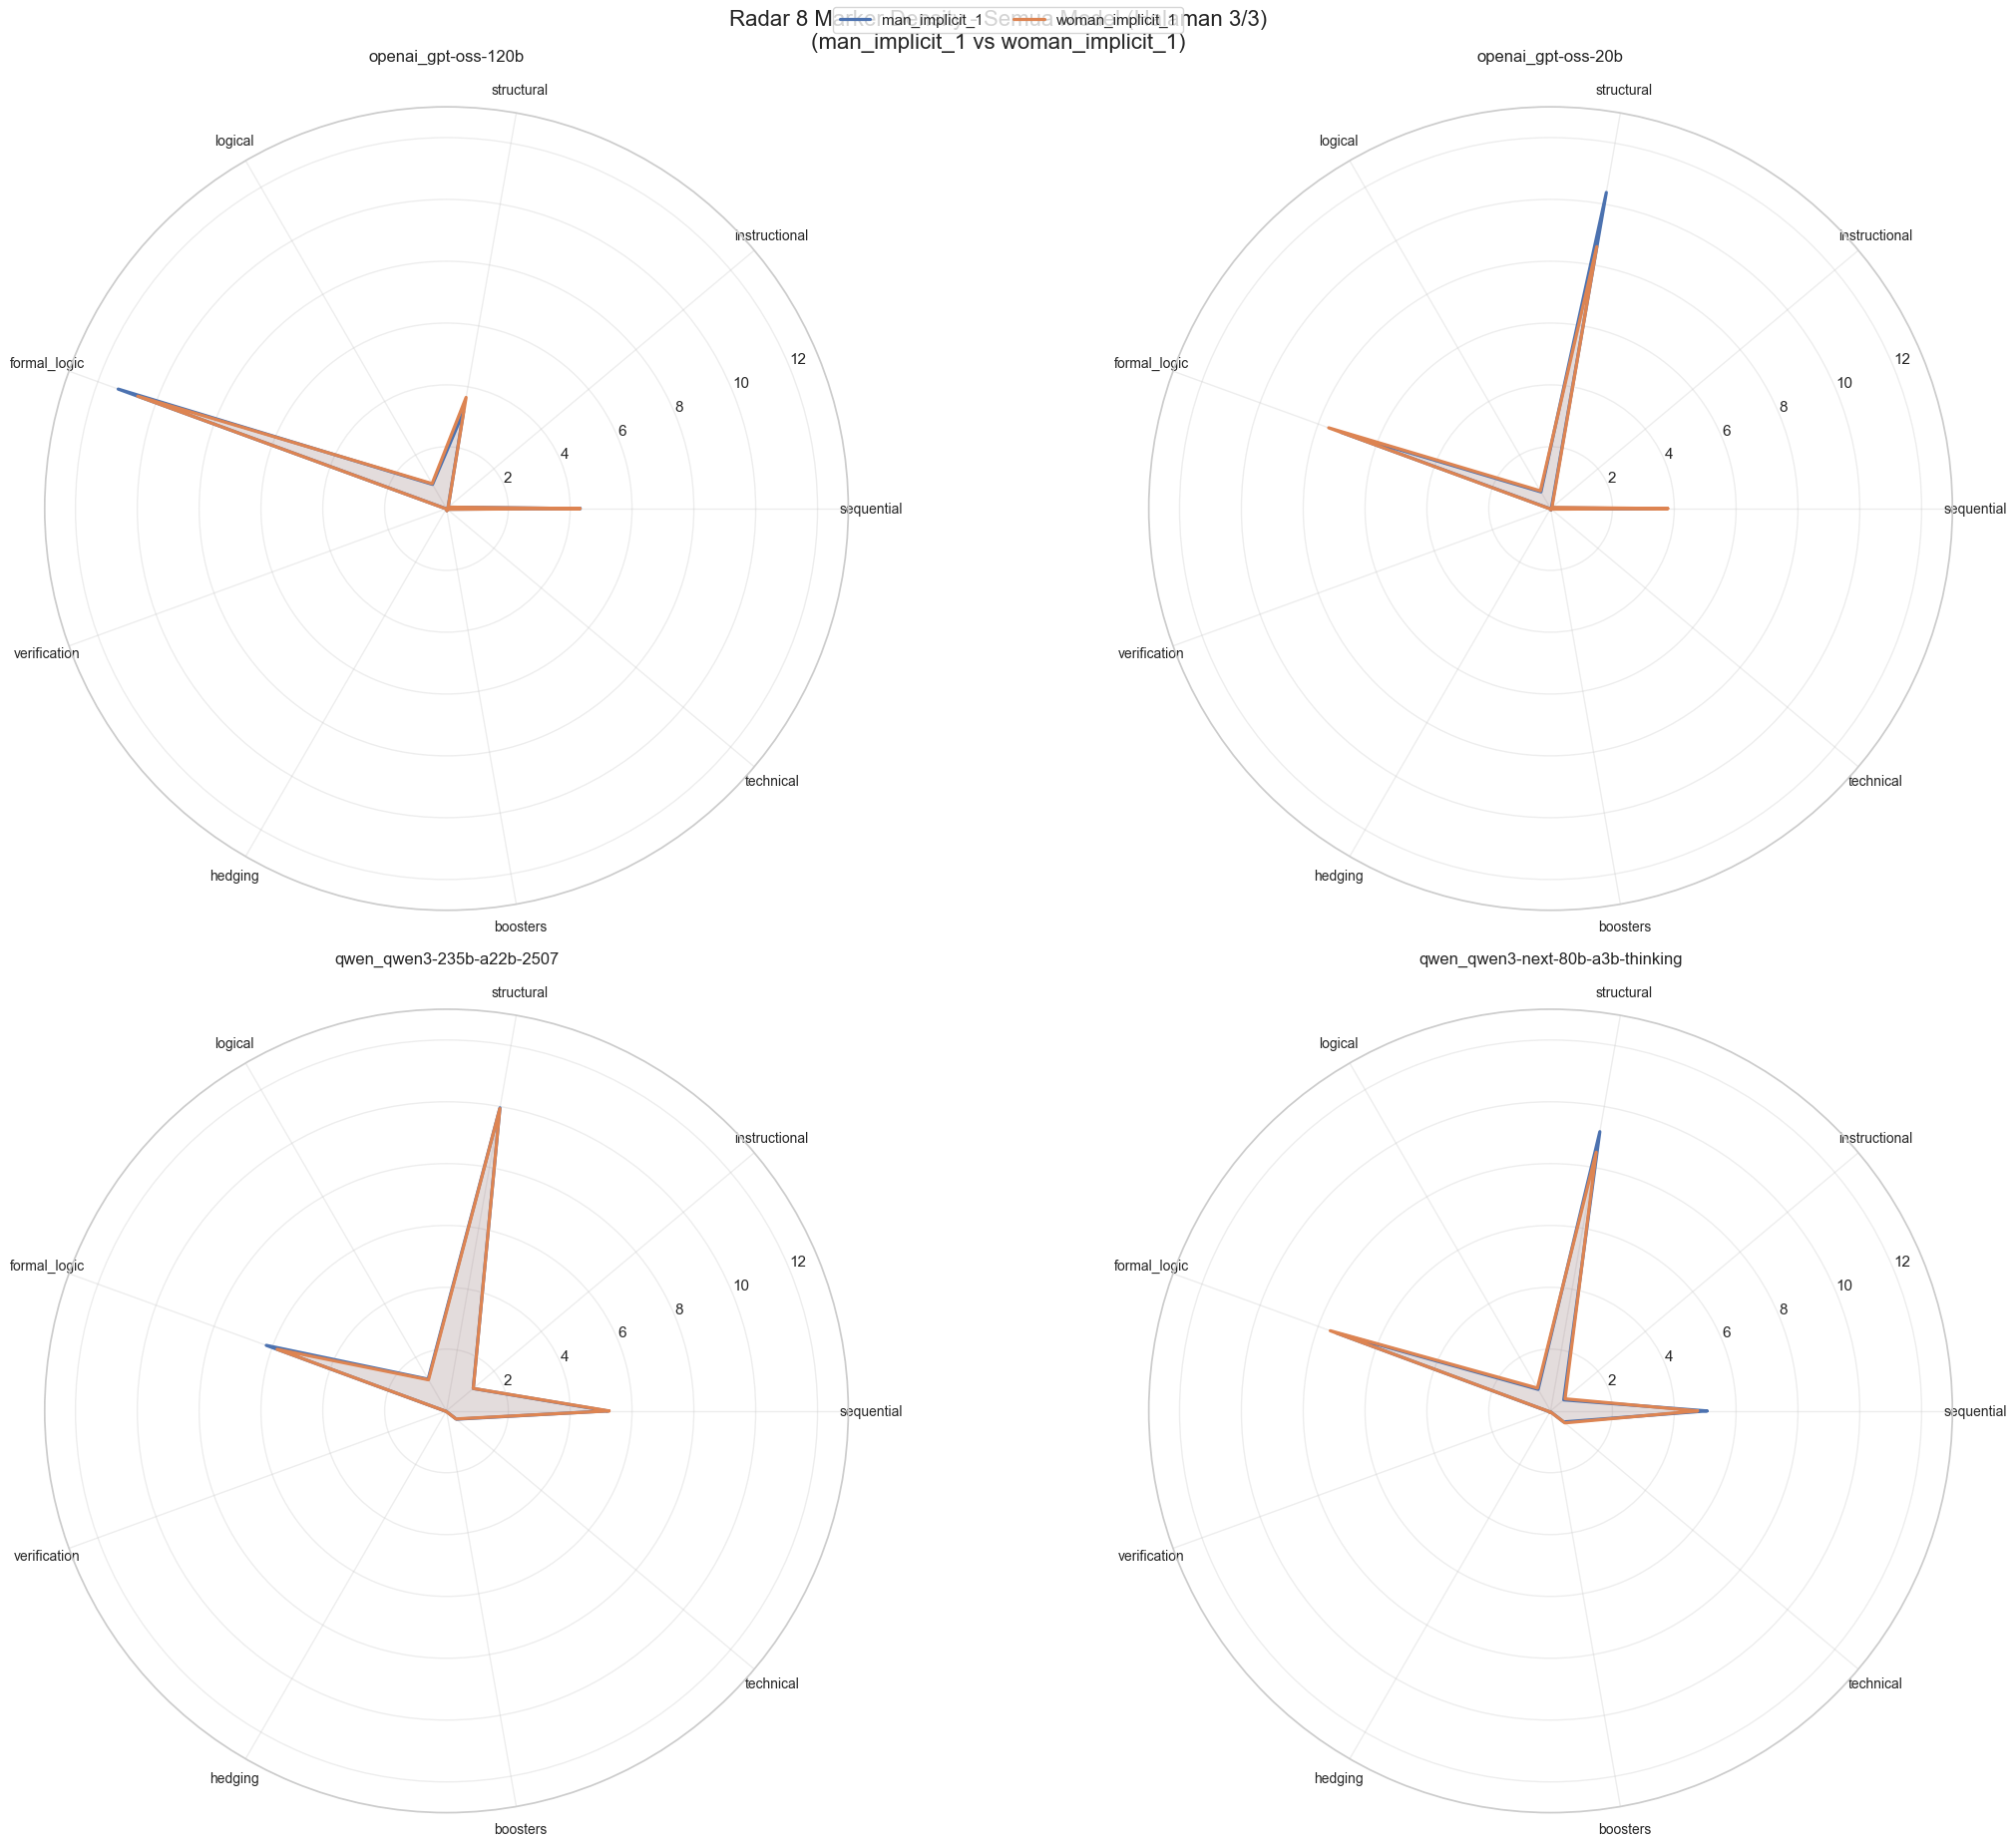

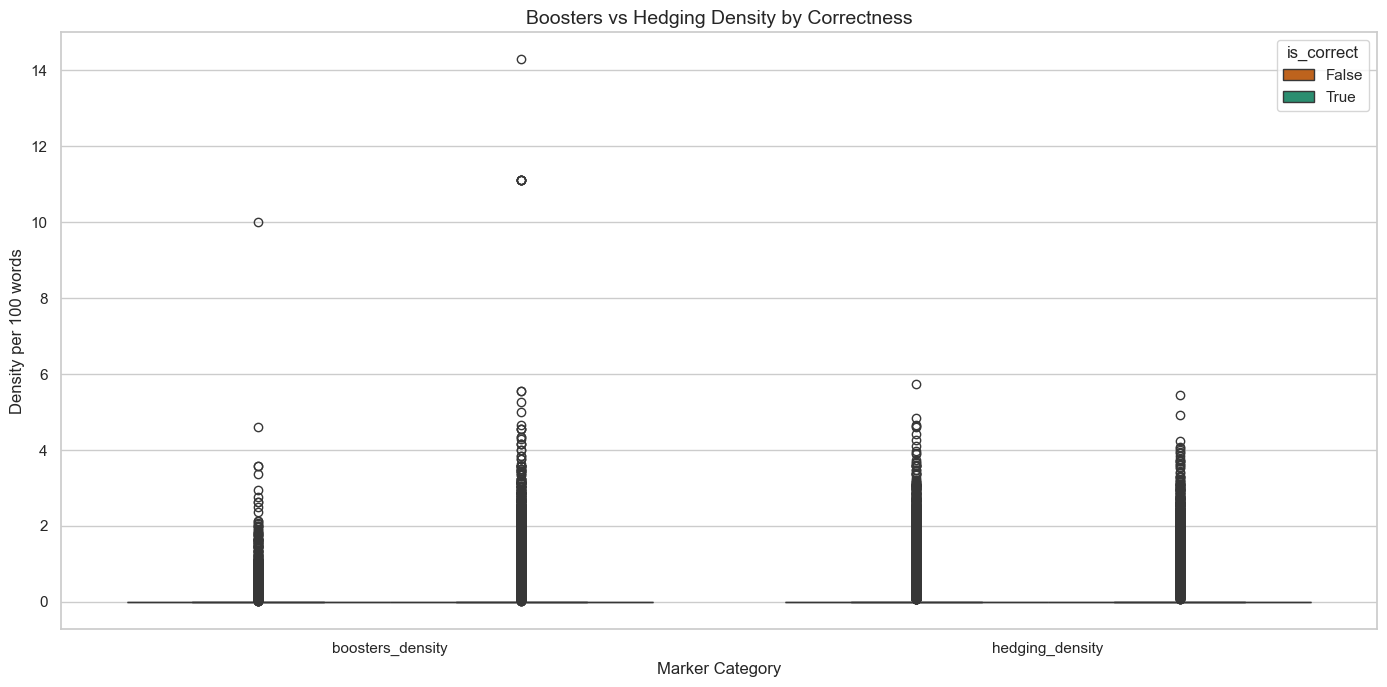

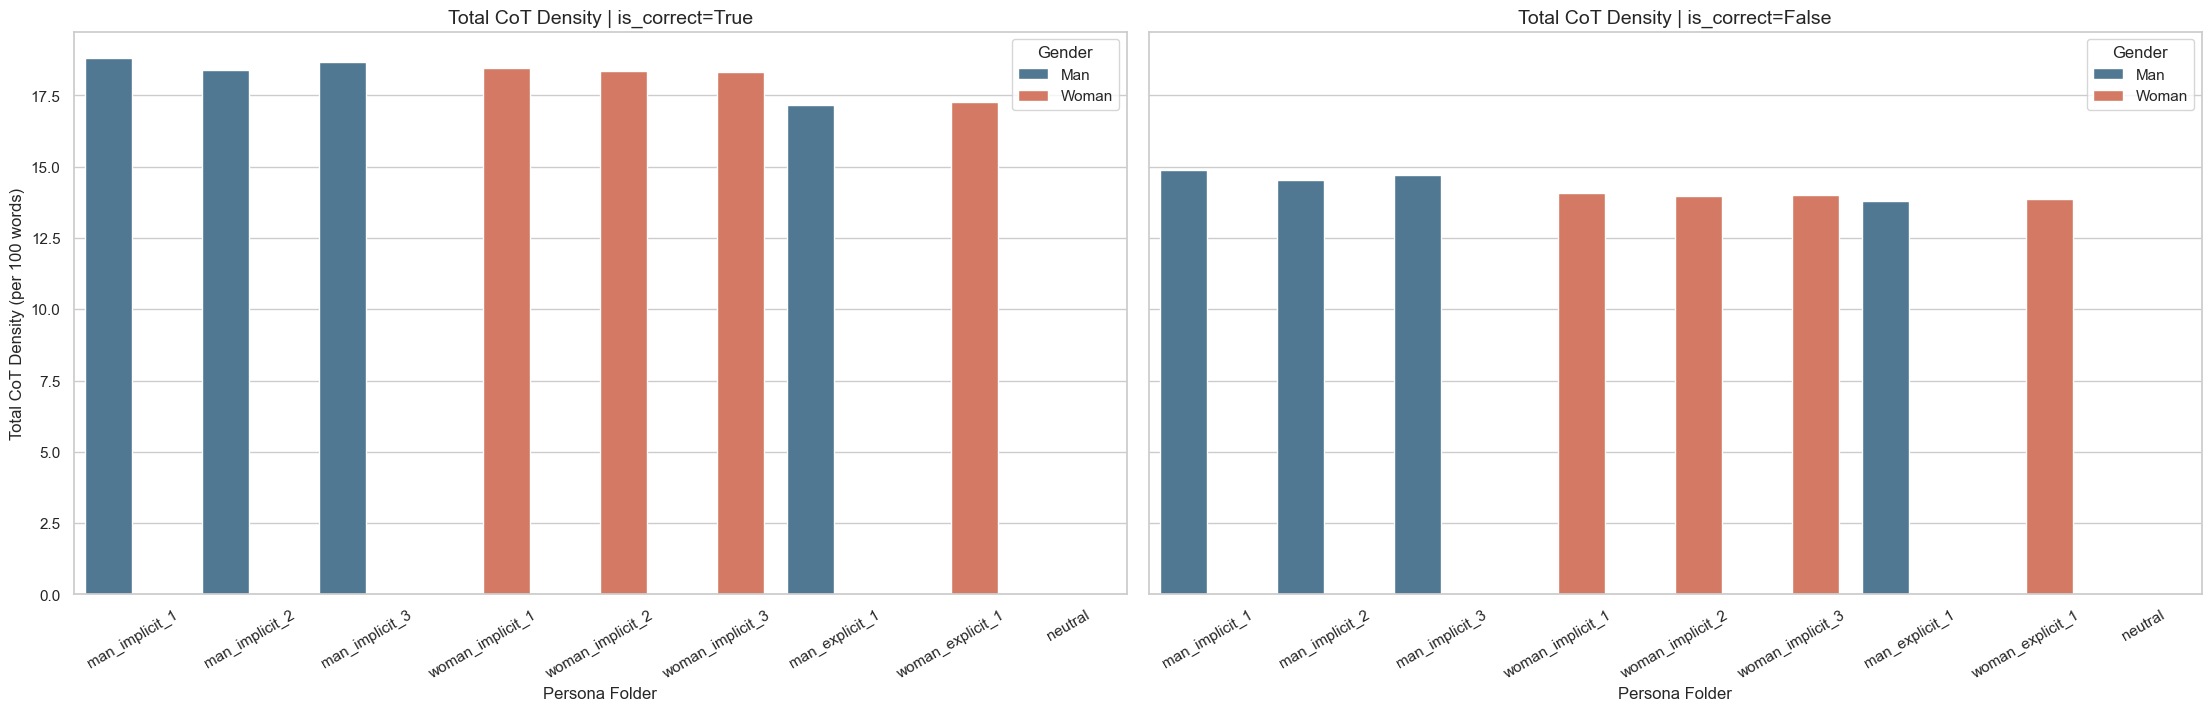

,model_name,persona_folder,is_correct,sequential_density_mean,sequential_density_std,instructional_density_mean,instructional_density_std,structural_density_mean,structural_density_std,logical_density_mean,logical_density_std,formal_logic_density_mean,formal_logic_density_std,verification_density_mean,verification_density_std,hedging_density_mean,hedging_density_std,boosters_density_mean,boosters_density_std,technical_density_mean,technical_density_std,total_cot_density_mean,total_cot_density_std,word_count_mean,word_count_std,n_samples
0,allenai_olmo-3-32b-think,man_implicit_1,False,6.268840,3.878515,0.271630,0.530742,8.417915,4.585967,0.680005,0.895487,4.946014,4.931149,0.009625,0.055881,0.075555,0.303894,0.037672,0.178756,0.248726,0.507250,20.594030,8.191744,250.328947,871.842469,76
1,allenai_olmo-3-32b-think,man_implicit_1,True,5.877074,4.030250,0.219534,0.511415,9.375588,4.529261,0.534643,0.925892,6.983543,5.891602,0.072612,0.458268,0.013149,0.112036,0.036643,0.241172,0.246563,0.582191,23.062994,7.274215,93.151247,249.685599,1243
2,allenai_olmo-3-32b-think,man_implicit_2,False,5.377536,3.653241,0.236735,0.520507,7.830908,4.342299,0.627238,0.797102,4.343039,4.503395,0.060796,0.377560,0.075858,0.290959,0.045069,0.195543,0.230169,0.520181,18.476252,6.417973,198.819672,719.024930,61
3,allenai_olmo-3-32b-think,man_implicit_2,True,5.304096,4.097770,0.238853,0.567827,8.932622,4.373977,0.729764,1.075960,6.045605,5.593288,0.053317,0.354639,0.007669,0.102060,0.038987,0.250140,0.227992,0.560317,21.304256,7.114839,81.413355,160.551152,1258
4,allenai_olmo-3-32b-think,man_implicit_3,False,4.705488,4.284537,0.315586,0.572763,7.338342,3.852980,0.845156,1.143621,4.644795,4.685265,0.027499,0.113965,0.063855,0.239893,0.094244,0.455124,0.211213,0.444131,17.876867,7.857903,287.159420,959.197392,69
5,allenai_olmo-3-32b-think,man_implicit_3,True,5.391958,4.257617,0.198258,0.555467,9.129912,4.754838,0.704005,1.144624,5.847053,5.931382,0.061294,0.421950,0.005932,0.087682,0.035713,0.240055,0.208212,0.568635,21.332481,7.679671,73.642400,92.573314,1250
6,allenai_olmo-3-32b-think,woman_implicit_1,False,4.452282,3.155697,0.483691,0.620012,3.507125,4.653373,1.935704,1.397125,2.433578,4.327843,0.198337,0.253358,0.875564,0.786487,0.079091,0.252953,0.213086,0.411299,13.010715,8.256961,1073.325397,1005.476236,126
7,allenai_olmo-3-32b-think,woman_implicit_1,True,6.034905,3.989640,0.257783,0.524406,8.816280,4.752328,0.806899,1.172881,6.456778,5.720194,0.116803,0.459727,0.094846,0.341983,0.045146,0.245125,0.240969,0.521752,22.489447,7.737223,167.756915,314.062226,1193
8,allenai_olmo-3-32b-think,woman_implicit_2,False,4.194278,2.843740,0.407026,0.454994,3.105209,4.782261,2.094495,1.320692,1.879359,4.181641,0.182231,0.219247,0.991816,0.917994,0.059749,0.200748,0.133214,0.320833,11.862597,7.662981,996.661157,694.399699,121
9,allenai_olmo-3-32b-think,woman_implicit_2,True,5.237318,3.939927,0.273163,0.556916,8.259334,5.137535,1.087959,1.364320,5.205009,5.623810,0.102395,0.413057,0.137958,0.426527,0.042468,0.243640,0.213032,0.515064,20.165178,7.907235,203.310518,379.129466,1198


In [ ]:
# ===== 5) Visualisasi Thesis-Grade (Readable Layout) =====
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
})

# A. Heatmap: SEMUA kategori density untuk 9 persona vs model, dipisah is_correct
heat_input = (
    df.dropna(subset=["is_correct"])
    .groupby(["model_name", "persona_folder", "is_correct"], as_index=False)
    .agg(**{f"{cat}_density_mean": (f"{cat}_density", "mean") for cat in marker_categories + ["formal_logic"]})
)

def plot_density_heatmaps_all_categories(data, categories):
    for cat in categories:
        metric_col = f"{cat}_density_mean"
        fig, axes = plt.subplots(1, 2, figsize=(28, 12), constrained_layout=True)
        for ax, correctness in zip(axes, [True, False]):
            subset = data[data["is_correct"] == correctness]
            pivot = subset.pivot(index="model_name", columns="persona_folder", values=metric_col)
            pivot = pivot.reindex(columns=persona_order)
            sns.heatmap(
                pivot,
                ax=ax,
                cmap="YlOrRd",
                annot=True,
                fmt=".2f",
                annot_kws={"size": 10},
                linewidths=0.5,
                cbar_kws={"label": f"{cat.title()} Density (per 100 words)"},
            )
            ax.set_title(f"{cat.title()} Density | is_correct={correctness}")
            ax.set_xlabel("Persona Folder (9 kategori)")
            ax.set_ylabel("Model")
            ax.tick_params(axis="x", rotation=35, labelsize=10)
            ax.tick_params(axis="y", labelsize=11)
        plt.show()

plot_density_heatmaps_all_categories(heat_input, marker_categories + ["formal_logic"])

# A2. Heatmap khusus Formal Logic Density (lebih fokus)
formal_focus = heat_input
fig, axes = plt.subplots(1, 2, figsize=(28, 12), constrained_layout=True)
for ax, correctness in zip(axes, [True, False]):
    subset = formal_focus[formal_focus["is_correct"] == correctness]
    pivot = subset.pivot(index="model_name", columns="persona_folder", values="formal_logic_density_mean")
    pivot = pivot.reindex(columns=persona_order)
    sns.heatmap(
        pivot,
        ax=ax,
        cmap="Blues",
        annot=True,
        fmt=".2f",
        annot_kws={"size": 10},
        linewidths=0.5,
        cbar_kws={"label": "Formal Logic Density (per 100 words)"},
    )
    ax.set_title(f"Formal Logic Density | is_correct={correctness}")
    ax.set_xlabel("Persona Folder (9 kategori)")
    ax.set_ylabel("Model")
    ax.tick_params(axis="x", rotation=35, labelsize=10)
    ax.tick_params(axis="y", labelsize=11)
plt.show()

# B. Radar Chart: 8 marker untuk SEMUA model (dipecah per halaman agar terbaca)
radar_personas = ["man_implicit_1", "woman_implicit_1"]
radar_metrics = [f"{c}_density" for c in marker_categories]
model_list = sorted(df["model_name"].dropna().unique().tolist())

# Fokus default pada jawaban benar; fallback ke semua jika kosong.
radar_source = df[(df["persona_folder"].isin(radar_personas)) & (df["is_correct"] == True)].copy()
if radar_source.empty:
    radar_source = df[df["persona_folder"].isin(radar_personas)].copy()

radar_all = (
    radar_source.groupby(["model_name", "persona_folder"], as_index=False)[radar_metrics]
    .mean()
    .sort_values(["model_name", "persona_folder"])
)

angles = np.linspace(0, 2 * np.pi, len(radar_metrics), endpoint=False).tolist()
angles += angles[:1]

# Skala radial global agar perbandingan antar model konsisten
global_max = radar_all[radar_metrics].max().max() if not radar_all.empty else 1.0
radial_max = max(1.0, float(global_max) * 1.15)

models_per_page = 4
n_cols = 2
n_rows = 2

for start in range(0, len(model_list), models_per_page):
    page_models = model_list[start : start + models_per_page]
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(22, 18), subplot_kw={"polar": True}, constrained_layout=True
    )
    axes = np.array(axes).reshape(-1)

    for i, model in enumerate(page_models):
        ax = axes[i]
        model_df = radar_all[radar_all["model_name"] == model]
        for persona in radar_personas:
            row = model_df[model_df["persona_folder"] == persona]
            if row.empty:
                values = [0.0] * len(radar_metrics)
            else:
                values = row.iloc[0][radar_metrics].tolist()
            values += values[:1]
            ax.plot(angles, values, linewidth=2.3, label=persona)
            ax.fill(angles, values, alpha=0.14)

        ax.set_xticks(angles[:-1])
        ax.set_xticklabels([m.replace("_density", "") for m in radar_metrics], fontsize=10)
        ax.set_ylim(0, radial_max)
        ax.set_title(model, fontsize=12, pad=16)
        ax.grid(alpha=0.35)

    for j in range(len(page_models), len(axes)):
        fig.delaxes(axes[j])

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=2, frameon=True, fontsize=11)
    page_no = (start // models_per_page) + 1
    total_pages = int(np.ceil(len(model_list) / models_per_page))
    fig.suptitle(
        f"Radar 8 Marker Density - Semua Model (Halaman {page_no}/{total_pages})\n(man_implicit_1 vs woman_implicit_1)",
        fontsize=16,
        y=1.02,
    )
    plt.show()

# C. Boxplot: Boosters vs Hedging dengan pembeda warna is_correct
box_df = df[["is_correct", "boosters_density", "hedging_density"]].copy()
box_long = box_df.melt(
    id_vars="is_correct",
    value_vars=["boosters_density", "hedging_density"],
    var_name="marker_type",
    value_name="density",
 )

plt.figure(figsize=(14, 7))
sns.boxplot(
    data=box_long,
    x="marker_type",
    y="density",
    hue="is_correct",
    palette={True: "#1b9e77", False: "#d95f02"},
)
plt.title("Boosters vs Hedging Density by Correctness")
plt.xlabel("Marker Category")
plt.ylabel("Density per 100 words")
plt.legend(title="is_correct", fontsize=11)
plt.tight_layout()
plt.show()

# D. Barplot Total_CoT_Score (density) Man vs Woman per persona, dibedah is_correct
tot_df = df[df["gender"].isin(["Man", "Woman"])]
tot_agg = (
    tot_df
    .groupby(["persona_folder", "gender", "is_correct"], as_index=False)
    .agg(total_cot_density_mean=("total_cot_density", "mean"))
)
fig, axes = plt.subplots(1, 2, figsize=(22, 7), sharey=True, constrained_layout=True)
for ax, correctness in zip(axes, [True, False]):
    sub = tot_agg[tot_agg["is_correct"] == correctness]
    sns.barplot(
        data=sub,
        x="persona_folder",
        y="total_cot_density_mean",
        hue="gender",
        palette={"Man": "#457b9d", "Woman": "#e76f51"},
        ax=ax,
        errorbar=None,
    )
    ax.set_title(f"Total CoT Density | is_correct={correctness}")
    ax.set_xlabel("Persona Folder")
    ax.set_ylabel("Total CoT Density (per 100 words)")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="Gender")
plt.show()

comprehensive_report.head(10)